# Long-tailed skin-lesion classification on ISIC 2019 — clean pipeline

**Question.** With only 10% of the labels, which of these helps the rare (tail) classes most: a better loss, synthetic lesions made by copy-paste with a *learned reliability weight*, or pseudo-labels for the unlabeled 85%?

**Everything is resumable.** Each training run is saved to Drive and skipped on re-run, so you can stop, disconnect and continue. Only the cell that was running restarts.

| # | Section | What it does | Time (T4, first run) |
|---|---|---|---|
| 1 | Setup and config | Drive, paths, all settings in one cell | seconds |
| 2 | Data checks | CSVs, class table, test-label check | seconds |
| 3 | Image cache | all training images resized once to 256 px | 15-30 min, then 3-5 min per session |
| 4 | Splits | 5 folds, grouped by lesion, stratified | seconds |
| 5 | Synthetic data (fold 0) | lesion masks, skin backgrounds, copy-paste generator, DINOv2 features | 20-30 min |
| 6 | Training tools | model, metrics, one generic runner | seconds |
| 7 | Baselines | CE, weighted CE, focal, logit adjustment (3 seeds) | ~40 min |
| 8 | Reliability features | quality, confidence, density, uncertainty per synthetic image | few min |
| 9 | Static synthetic data | synthetic images at fixed weights, plus a real-vs-fake probe | ~60 min |
| 10 | Learned reliability filter | bi-level training and controls | ~2 h |
| 11 | Pseudo-labeling | use the unlabeled pool, threshold check | ~1 h |
| 12 | Official test set | the saved models scored on the 6,191 official test images | ~15 min |
| 13 | Five folds | key methods on all folds | ~1 h |
| 14 | Summary | tables and figures saved to `DS_PROJECT/report/` | seconds |

**Where things are saved** (all inside `DS_PROJECT` on Drive): `cache/` resized images, `splits/` fold tables, `gen/` masks, backgrounds, synthetic images and features, `runs/fold*/<run>/` one folder per experiment (`result.json`, `best.pt`, `test_logits.npy`), `report/` final tables and figures.

**Deviations from the original design (stated plainly).** Lesion copy-paste replaces latent diffusion; BCC is its own middle tier (it was missing from the routing); the bi-level update touches only the classifier head, with a one-step look-ahead; an extra 5% labeled meta set drives that update; the corrected class counts are used (the four tail classes total about 2,000 images, not 5,000).

**Additions after the first runs (this version).** 5.1b improved lesion masks (GrabCut, restricted to the dermoscope field of view, with a quality check); 12b inference boosts (4x flip TTA and a 3-seed ensemble on the saved models, no retraining); 12c early-stopping replay on the saved training histories; 14b headline table, figure and report sentences. A retraining with EfficientNet-B2 + early stopping was tried and did **not** help (single-model BMA 0.465 vs 0.496 for `la_L`, 0.479 vs 0.525 for `pl_la_t08`), so the EfficientNet-B0 pipeline above is the final one.

## 1. Setup and config

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, glob, shutil, zipfile, time, gc, copy, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from multiprocessing import Pool
from sklearn.model_selection import StratifiedGroupKFold
import torch
warnings.filterwarnings('ignore')
dev = 'cuda' if torch.cuda.is_available() else 'cpu'

# ---------------- paths ----------------
ROOT = Path('/content/drive/MyDrive/DS_PROJECT')
CACHE_DRIVE, SPLITS, RUNS, GEN, REPORT = ROOT/'cache', ROOT/'splits', ROOT/'runs', ROOT/'gen', ROOT/'report'
for p in (CACHE_DRIVE, SPLITS, RUNS, GEN, REPORT): p.mkdir(parents=True, exist_ok=True)

def find(pattern):
    """Find the one file in ROOT whose name contains `pattern` (your files start with 'Copy of')."""
    hits = [p for p in ROOT.glob('*') if pattern in p.name]
    assert len(hits) == 1, f'expected exactly one match for {pattern!r}, got {hits}'
    return hits[0]

GT_TRAIN, META_TRAIN, ZIP_TRAIN = find('Training_GroundTruth.csv'), find('Training_Metadata.csv'), find('Training_Input.zip')
GT_TEST,  META_TEST,  ZIP_TEST  = find('Test_GroundTruth.csv'),     find('Test_Metadata.csv'),     find('Test_Input.zip')

# ---------------- data and split settings ----------------
SEED       = 42
IMG_SIZE   = 256          # cache resolution (shorter side resized, then centre crop)
N_FOLDS    = 5
META_FRAC  = 0.05         # labeled meta set (drives the reliability filter and picks the best epoch)
LABEL_FRAC = 0.10         # labeled set D_L; the other ~85% of each fold's training part is the unlabeled pool D_U
                          # (the split cell cuts each training part into 20 slices: 1 meta + 2 labeled + 17 unlabeled)
CLASSES = ['MEL','NV','BCC','AK','BKL','DF','VASC','SCC']      # UNK is empty in training
C2I  = {c: i for i, c in enumerate(CLASSES)}
TAIL = ['AK','DF','VASC','SCC']      # rare classes -> receive synthetic images
MID  = ['BCC']                       # middle tier
HEAD = ['NV','MEL','BKL']
TIER = {**{c:'tail' for c in TAIL}, **{c:'mid' for c in MID}, **{c:'head' for c in HEAD}}
K = len(CLASSES); TAIL_IDX = [C2I[c] for c in TAIL]

LOCAL = Path('/content/isic'); LOCAL.mkdir(exist_ok=True)
CACHE_LOCAL = LOCAL / f'cache{IMG_SIZE}'
CACHE_ZIP   = CACHE_DRIVE / f'train_cache{IMG_SIZE}.zip'

# ---------------- training settings (identical for every run; saved runs refuse to be reused with other settings) ----------------
TCFG = dict(arch='efficientnet_b0', epochs=15, bs=64, lr=3e-4, wd=1e-4, crop=224, seed=SEED)
SEEDS = [42, 1, 2]                                           # 42 keeps plain run names, other seeds get a _s<seed> suffix

# ---------------- synthetic data and reliability filter settings ----------------
SYN_FOLD, N_BG, SYN_TAG = 0, 1500, 'cp_v1'
N_SYN  = {'AK': 600, 'DF': 600, 'VASC': 600, 'SCC': 600}     # synthetic images per tail class
FEATS  = ['Q_nn', 'C', 'D', 'U']                             # quality, confidence, class density, uncertainty
BCFG   = dict(meta_every=2, meta_bs=64, virtual_lr=0.1, theta_lr=0.05, warmup_ep=2)

json.dump(dict(SEED=SEED, IMG_SIZE=IMG_SIZE, N_FOLDS=N_FOLDS, META_FRAC=META_FRAC, LABEL_FRAC=LABEL_FRAC, CLASSES=CLASSES,
               TAIL=TAIL, MID=MID, HEAD=HEAD, TCFG=TCFG, SEEDS=SEEDS, N_SYN=N_SYN, BCFG=BCFG, FEATS=FEATS),
          open(ROOT / 'config.json', 'w'), indent=2)
print('GPU:', torch.cuda.get_device_name(0) if dev == 'cuda' else 'none (sections 6 onwards need a GPU)')
for p in (GT_TRAIN, META_TRAIN, ZIP_TRAIN, GT_TEST, META_TEST, ZIP_TEST): print(' ', p.name)

Mounted at /content/drive
GPU: Tesla T4
  Copy of ISIC_2019_Training_GroundTruth.csv
  Copy of ISIC_2019_Training_Metadata.csv
  Copy of ISIC_2019_Training_Input.zip
  Copy of ISIC_2019_Test_GroundTruth.csv
  Copy of ISIC_2019_Test_Metadata.csv
  Copy of ISIC_2019_Test_Input.zip


## 2. Data checks

In [ ]:
gt   = pd.read_csv(GT_TRAIN)
meta = pd.read_csv(META_TRAIN)
print('GT   :', gt.shape,   list(gt.columns))
print('META :', meta.shape, list(meta.columns))

assert len(gt) == 25331, f'expected 25,331 rows, got {len(gt)}'
assert set(CLASSES) <= set(gt.columns), 'missing class columns'
assert (gt[CLASSES].sum(1) == 1).all(), 'some rows are not one-hot over the 8 classes'
if 'UNK' in gt: print('UNK images in training:', int(gt['UNK'].sum()), '(expected 0)')
assert gt['image'].is_unique

df = gt[['image'] + CLASSES].merge(meta, on='image', how='left')
assert len(df) == len(gt)
df['label'] = df[CLASSES].values.argmax(1)
df['cls']   = df['label'].map(dict(enumerate(CLASSES)))
df['tier']  = df['cls'].map(TIER)

# --- grouping column: images of the same lesion must stay on the same side of every split ---
if 'lesion_id' in df.columns:
    n_missing = df['lesion_id'].isna().sum()
    df['group'] = df['lesion_id'].fillna(df['image'])      # no lesion_id -> its own group
    sizes = df.groupby('group').size()
    print(f'lesion_id missing for {n_missing} images; {int((sizes>1).sum())} lesions have >1 image '
          f'({int(sizes[sizes>1].sum())} images affected)')
else:
    df['group'] = df['image']
    print('WARNING: no lesion_id column, falling back to image-level split')

tab = df.groupby('cls').size().reindex(CLASSES).to_frame('n')
tab['share_%'] = (100*tab['n']/len(df)).round(2)
tab['tier'] = [TIER[c] for c in tab.index]
display(tab)
print('imbalance ratio NV / DF =', round(tab.loc['NV','n']/tab.loc['DF','n'], 1))
print('tail total =', int(tab[tab.tier=="tail"].n.sum()), '| head total =', int(tab[tab.tier=="head"].n.sum()))

# metadata the reliability filter may use later
for c in ['age_approx','sex','anatom_site_general']:
    if c in df.columns: print(f'{c}: {df[c].isna().mean()*100:.1f}% missing')

GT   : (25331, 10) ['image', 'MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC', 'UNK']
META : (25331, 5) ['image', 'age_approx', 'anatom_site_general', 'lesion_id', 'sex']
UNK images in training: 0 (expected 0)
lesion_id missing for 2084 images; 5059 lesions have >1 image (16459 images affected)


,n,share_%,tier
cls,,,
MEL,4522,17.85,head
NV,12875,50.83,head
BCC,3323,13.12,mid
AK,867,3.42,tail
BKL,2624,10.36,head
DF,239,0.94,tail
VASC,253,1.00,tail
SCC,628,2.48,tail


imbalance ratio NV / DF = 53.9
tail total = 1987 | head total = 20021
age_approx: 1.7% missing
sex: 1.5% missing
anatom_site_general: 10.4% missing


**Does the test ground-truth file have real labels?** The official ISIC 2019 test labels were once unpublished, so this is checked instead of assumed. The test set also contains an `UNK` class that our 8-class model cannot predict; it is excluded from evaluation.

In [ ]:
t = pd.read_csv(GT_TEST)
print(t.shape, list(t.columns))
display(t.head(3))
cols = [c for c in CLASSES + ['UNK'] if c in t.columns]
if len(cols) >= 8:
    onehot = (t[cols].sum(1) == 1).mean()
    print(f'rows that are valid one-hot labels: {onehot*100:.1f}%')
    print(t[cols].sum().astype(int).to_dict())
    HAS_TEST_LABELS = onehot > 0.99 and t[cols].sum().min() >= 0
    print('\n=> TEST LABELS AVAILABLE, can be used as an extra held-out evaluation.' if HAS_TEST_LABELS
          else '\n=> file exists but is not a usable label table.')
else:
    HAS_TEST_LABELS = False
    print('=> not a label table with class columns; do NOT use it for evaluation.')
if HAS_TEST_LABELS and 'UNK' in t.columns:
    print('Note: the test set also has an UNK class (images from outside the 8 classes). '
          'Our 8-class model cannot predict it, so report test scores on the 8 known classes only.')

(8238, 12) ['image', 'MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC', 'UNK', 'score_weight', 'validation_weight']


,image,MEL,NV,BCC,AK,BKL,DF,VASC,SCC,UNK,score_weight,validation_weight
0,ISIC_0034321,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,ISIC_0034322,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,ISIC_0034323,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


rows that are valid one-hot labels: 100.0%
{'MEL': 1327, 'NV': 2495, 'BCC': 975, 'AK': 374, 'BKL': 660, 'DF': 91, 'VASC': 104, 'SCC': 165, 'UNK': 2047}

=> TEST LABELS AVAILABLE, can be used as an extra held-out evaluation.
Note: the test set also has an UNK class (images from outside the 8 classes). Our 8-class model cannot predict it, so report test scores on the 8 known classes only.


## 3. Image cache (256 px)
The raw zip is 9.1 GB. Every image is resized **once** (shorter side to 256, centre crop) and stored as a JPEG on the local disk, then packed into **one zip on Drive**. Later sessions only unzip it. Nothing on Drive is deleted or overwritten.

In [ ]:
def cache_complete():
    return CACHE_LOCAL.exists() and len(list(CACHE_LOCAL.glob('*.jpg'))) >= len(df)

_zf = None
def _init(zpath):
    global _zf; _zf = zipfile.ZipFile(zpath)

def _resize_one(args):
    name, out = args
    try:
        if os.path.exists(out): return 1
        im = Image.open(_zf.open(name)).convert('RGB')
        w, h = im.size; s = IMG_SIZE / min(w, h)
        im = im.resize((max(IMG_SIZE, round(w*s)), max(IMG_SIZE, round(h*s))), Image.LANCZOS)
        w, h = im.size; l, t = (w-IMG_SIZE)//2, (h-IMG_SIZE)//2
        im.crop((l, t, l+IMG_SIZE, t+IMG_SIZE)).save(out, quality=95)
        return 1
    except Exception as e:
        print('FAILED', name, e); return 0

if cache_complete():
    print('local cache already present:', len(list(CACHE_LOCAL.glob("*.jpg"))), 'images')
elif CACHE_ZIP.exists():
    print('restoring cache from Drive zip ...'); CACHE_LOCAL.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(CACHE_ZIP) as z: z.extractall(CACHE_LOCAL)
    print('restored', len(list(CACHE_LOCAL.glob("*.jpg"))), 'images')
else:
    t0 = time.time()
    local_zip = LOCAL / 'train_input.zip'
    if not local_zip.exists():
        print('copying the 9.1 GB zip to local disk (one time) ...'); shutil.copyfile(ZIP_TRAIN, local_zip)
    CACHE_LOCAL.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(local_zip) as z:
        names = {Path(n).stem: n for n in z.namelist() if n.lower().endswith('.jpg')}
    missing = set(df['image']) - set(names)
    assert not missing, f'{len(missing)} images from the CSV are not in the zip, e.g. {list(missing)[:3]}'
    jobs = [(names[i], str(CACHE_LOCAL / f'{i}.jpg')) for i in df['image']]
    with Pool(os.cpu_count(), initializer=_init, initargs=(str(local_zip),)) as pool:
        ok = sum(pool.imap_unordered(_resize_one, jobs, chunksize=64))
    print(f'resized {ok}/{len(jobs)} in {(time.time()-t0)/60:.1f} min')
    assert ok == len(jobs), 'some images failed, re-run this cell (finished ones are skipped)'
    print('packing cache into one zip on Drive ...')
    tmp = CACHE_ZIP.with_suffix('.tmp')
    with zipfile.ZipFile(tmp, 'w', zipfile.ZIP_STORED) as z:
        for f in sorted(CACHE_LOCAL.glob('*.jpg')): z.write(f, f.name)
    tmp.rename(CACHE_ZIP)                       # only appears under its final name when complete
    os.remove(local_zip)                         # local copy only, Drive original untouched
    print('saved', CACHE_ZIP.name, f'{CACHE_ZIP.stat().st_size/1e9:.2f} GB')

assert cache_complete()
im = Image.open(CACHE_LOCAL / f'{df.image[0]}.jpg'); print('example image size:', im.size)

restoring cache from Drive zip ...
restored 25331 images
example image size: (256, 256)


## 4. Splits: 5 folds, grouped by lesion, stratified by class
For each fold: **test** = the held-out 20% (never used for training or selection). The other 80% is cut into 20 grouped, stratified slices of 5%: 1 slice is **meta** (labeled; picks the best epoch and trains the reliability filter), 2 slices are **L** (the labeled set D_L, 10%), and 17 slices are **U** (unlabeled pool D_U; its labels are kept in the table only to *score* pseudo-labels and must never be used for training).

In [ ]:
def make_fold(k, tr_idx, te_idx):
    sub = df.iloc[tr_idx]
    sgk = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED + k)
    parts = [p for _, p in sgk.split(sub, sub['label'], sub['group'])]
    role = pd.Series('U', index=df.index)
    role.iloc[te_idx] = 'test'
    role.iloc[sub.index[parts[0]]] = 'meta'
    role.iloc[sub.index[np.concatenate([parts[1], parts[2]])]] = 'L'
    out = df[['image','cls','label','tier','group','age_approx','sex','anatom_site_general']].copy()
    out['role'] = role.values; out['fold'] = k
    return out

sgk5 = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = {}
for k, (tr, te) in enumerate(sgk5.split(df, df['label'], df['group'])):
    f = SPLITS / f'fold{k}.csv'
    if f.exists():
        folds[k] = pd.read_csv(f)
    else:
        folds[k] = make_fold(k, tr, te); folds[k].to_csv(f, index=False)
print('splits ready:', sorted(p.name for p in SPLITS.glob('fold*.csv')))

# ---------- integrity checks ----------
for k, f in folds.items():
    assert len(f) == len(df) and f['image'].is_unique
    roles = f.groupby('group')['role'].apply(set)
    assert all(r == {'test'} or 'test' not in r for r in roles), f'fold {k}: a lesion appears in test AND training'
    assert set(f['role']) == {'L','U','meta','test'}
print('no lesion leaks between test and training in any fold')
# test folds must partition the dataset
assert sorted(sum([f.query("role=='test'")['image'].tolist() for f in folds.values()], [])) == sorted(df['image'])
print('the 5 test folds cover every image exactly once')

f0 = folds[0]
cnt = f0.groupby(['cls','role']).size().unstack(fill_value=0).reindex(CLASSES)[['L','U','meta','test']]
cnt['total'] = cnt.sum(1)
display(cnt)
print('Labeled DF images in D_L (fold 0):', int(cnt.loc['DF','L']), '| in meta:', int(cnt.loc['DF','meta']))

splits ready: ['fold0.csv', 'fold1.csv', 'fold2.csv', 'fold3.csv', 'fold4.csv']
no lesion leaks between test and training in any fold
the 5 test folds cover every image exactly once


role,L,U,meta,test,total
cls,,,,,
MEL,386,3121,172,843,4522
NV,961,8892,523,2499,12875
BCC,265,2185,136,737,3323
AK,95,560,58,154,867
BKL,213,1747,137,527,2624
DF,17,161,8,53,239
VASC,28,142,7,76,253
SCC,47,449,17,115,628


Labeled DF images in D_L (fold 0): 17 | in meta: 8


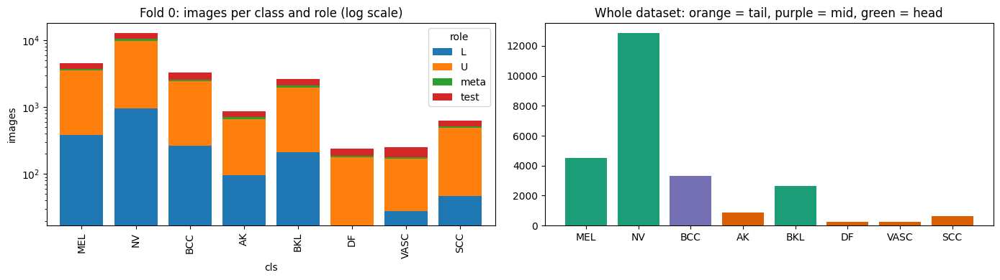

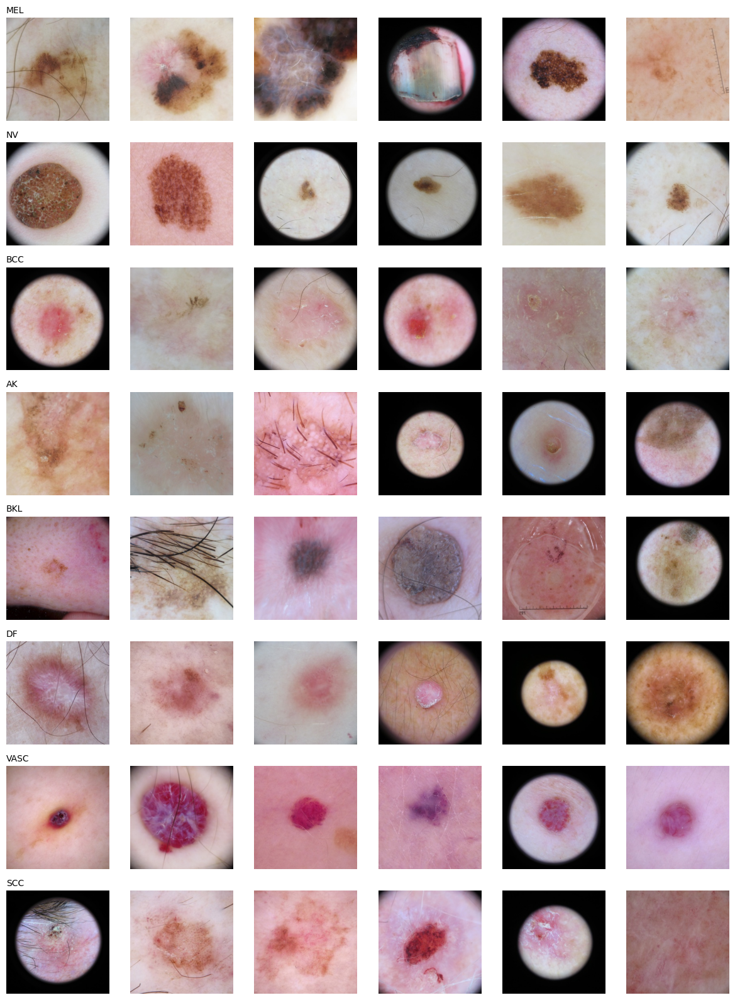

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
cnt[['L','U','meta','test']].plot.bar(stacked=True, ax=ax[0], width=.8)
ax[0].set_yscale('log'); ax[0].set_title('Fold 0: images per class and role (log scale)'); ax[0].set_ylabel('images')
ax[1].bar(CLASSES, tab['n'].values, color=['#d95f02' if TIER[c]=='tail' else '#1b9e77' if TIER[c]=='head' else '#7570b3' for c in CLASSES])
ax[1].set_title('Whole dataset: orange = tail, purple = mid, green = head')
plt.tight_layout(); plt.show()

# 6 random cached images per class
fig, axes = plt.subplots(len(CLASSES), 6, figsize=(12, 2*len(CLASSES)))
rng = np.random.default_rng(SEED)
for r, c in enumerate(CLASSES):
    ids = rng.choice(df.loc[df.cls == c, 'image'].values, 6, replace=False)
    for j, i in enumerate(ids):
        axes[r, j].imshow(Image.open(CACHE_LOCAL / f'{i}.jpg')); axes[r, j].axis('off')
    axes[r, 0].set_title(c, loc='left', fontsize=10)
plt.tight_layout(); plt.show()

## 5. Synthetic data on fold 0 (copy-paste generator)
Steps: lesion masks for every image, a bank of lesion-free skin backgrounds, the generator, and DINOv2 embeddings for the first reliability feature. Lesion sources are the **labeled tail images of D_L only**; meta and test images are never used.

### 5.1 Lesion masks (classical segmentation, saved once to Drive)

In [ ]:
# ===== PART 2 · CELL 1 · Lesion masks (classical segmentation, saved once to Drive) =====
import cv2
S = IMG_SIZE
MASK_FILE  = GEN / 'masks_packed.npy'      # one bit per pixel, row i = df.iloc[i]
MASK_STATS = GEN / 'mask_stats.csv'
IDX = {im: i for i, im in enumerate(df['image'])}

def segment(i):
    im   = cv2.imread(str(CACHE_LOCAL / f'{i}.jpg'))
    lab  = cv2.cvtColor(im, cv2.COLOR_BGR2LAB).astype(np.float32)
    gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    valid = cv2.morphologyEx((gray > 25).astype(np.uint8), cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    valid_frac = float(valid.mean())
    yy, xx = np.mgrid[:S, :S]; r = np.hypot(yy - S/2, xx - S/2) / (S/2)
    ring = (valid > 0) & (r > 0.55)                       # outer part of the visible field = skin
    if ring.sum() < 500: ring = valid > 0
    skin = np.median(lab[ring], axis=0)
    dist = cv2.GaussianBlur(np.sqrt(((lab - skin) ** 2).sum(2)), (0, 0), 2)
    d8 = np.clip(dist / max(float(dist[valid > 0].max()), 1e-6) * 255, 0, 255).astype(np.uint8)
    d8[valid == 0] = 0
    thr, _ = cv2.threshold(d8[valid > 0].reshape(-1, 1), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    m = ((d8 > thr) & (valid > 0)).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN,  np.ones((5, 5), np.uint8))
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8))
    n, lbl, st, cen = cv2.connectedComponentsWithStats(m)
    if n <= 1:
        return np.packbits(np.zeros(S * S, np.uint8)), 0.0, 0.0, valid_frac
    best, bs = 1, -1
    for c in range(1, n):                                  # biggest component, preferring the centre
        dc = np.hypot(cen[c][0] - S/2, cen[c][1] - S/2) / (S/2)
        sc = st[c, cv2.CC_STAT_AREA] * (1 - 0.7 * min(dc, 1))
        if sc > bs: bs, best = sc, c
    m = (lbl == best).astype(np.uint8)
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    m = np.zeros_like(m); cv2.drawContours(m, cnts, -1, 1, -1)       # fill holes
    touch = (m[:3].sum() + m[-3:].sum() + m[:, :3].sum() + m[:, -3:].sum()) / (4 * 3 * S)
    return np.packbits(m.ravel()), float(m.mean()), float(touch), valid_frac

if MASK_FILE.exists() and MASK_STATS.exists():
    print('masks already on Drive, loading')
else:
    t0 = time.time()
    with Pool(os.cpu_count()) as pool:
        res = list(pool.imap(segment, df['image'].tolist(), chunksize=64))
    arr = np.stack([r[0] for r in res])
    st_df = pd.DataFrame({'image': df['image'], 'area': [r[1] for r in res],
                          'border_touch': [r[2] for r in res], 'valid_frac': [r[3] for r in res]})
    st_df['ok'] = st_df['area'].between(0.02, 0.65) & (st_df['border_touch'] < 0.15)
    np.save(GEN / 'masks_tmp.npy', arr); (GEN / 'masks_tmp.npy').rename(MASK_FILE)
    st_df.to_csv(MASK_STATS, index=False)
    print(f'segmented {len(df)} images in {(time.time()-t0)/60:.1f} min')

MASKS = np.load(MASK_FILE)
mstat = pd.read_csv(MASK_STATS)
def get_mask(i):                         # i = row index in df
    return np.unpackbits(MASKS[i])[:S * S].reshape(S, S)
df['mask_ok'] = mstat['ok'].values
df['mask_area'] = mstat['area'].values
df['valid_frac'] = mstat['valid_frac'].values
display(df.groupby('cls')[['mask_ok', 'mask_area']].mean().reindex(CLASSES).round(3))

masks already on Drive, loading


,mask_ok,mask_area
cls,,
MEL,0.806,0.182
NV,0.906,0.176
BCC,0.683,0.119
AK,0.581,0.131
BKL,0.822,0.149
DF,0.841,0.160
VASC,0.877,0.138
SCC,0.734,0.134


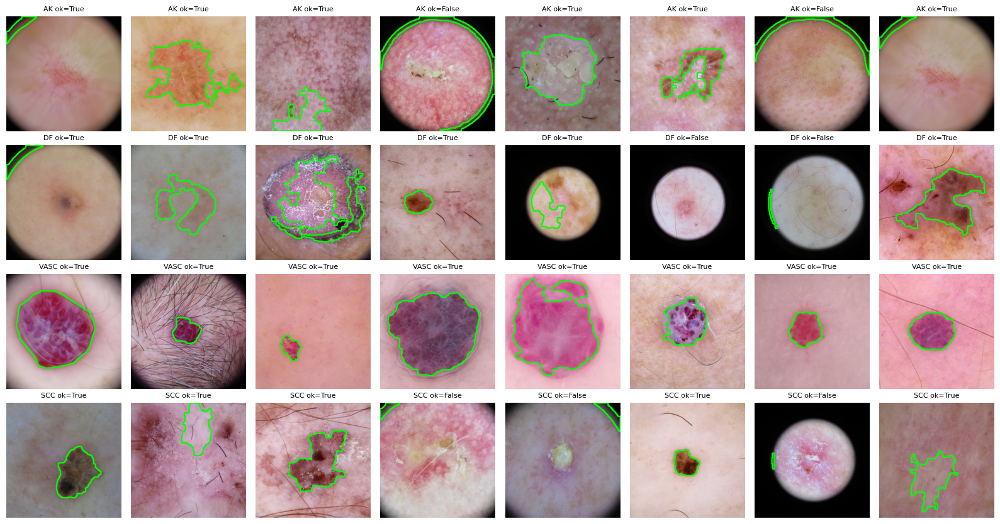

Green line should follow the lesion edge. If most tail masks look wrong, tell me before running the next cells.


In [ ]:
# ===== PART 2 · CELL 2 · LOOK AT THE MASKS (judge quality before going on) =====
fig, axes = plt.subplots(len(TAIL), 8, figsize=(16, 2.1 * len(TAIL)))
rng = np.random.default_rng(1)
for r, c in enumerate(TAIL):
    ids = rng.choice(np.where(df.cls == c)[0], 8, replace=False)
    for j, i in enumerate(ids):
        im = cv2.cvtColor(cv2.imread(str(CACHE_LOCAL / f'{df.image[i]}.jpg')), cv2.COLOR_BGR2RGB)
        cnts, _ = cv2.findContours(get_mask(i).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(im, cnts, -1, (0, 255, 0), 2)
        axes[r, j].imshow(im); axes[r, j].axis('off')
        axes[r, j].set_title(f"{c} ok={bool(df.mask_ok[i])}", fontsize=8)
plt.tight_layout(); plt.show()
print('Green line should follow the lesion edge. If most tail masks look wrong, tell me before running the next cells.')

### 5.1b Better lesion masks (optional; run after looking at the masks above)
GrabCut moves the boundary of the old mask onto the real colour edge. Only the labeled tail images (the lesion sources of the generator) are refined, and the old masks stay untouched on Drive.

refined 187 tail masks in 42 s


,iou_old_new,area_old,area_new,unchanged
cls,,,,
AK,0.840,0.124,0.128,0.547
DF,0.893,0.131,0.136,0.412
SCC,0.812,0.120,0.135,0.319
VASC,0.874,0.130,0.137,0.143


masks where the sanity check kept the old mask: 78 of 187


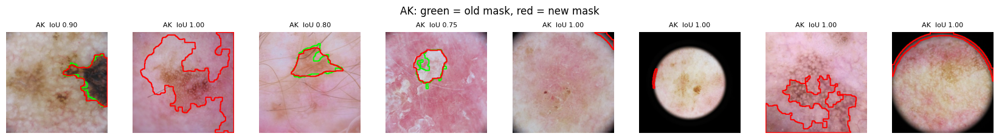

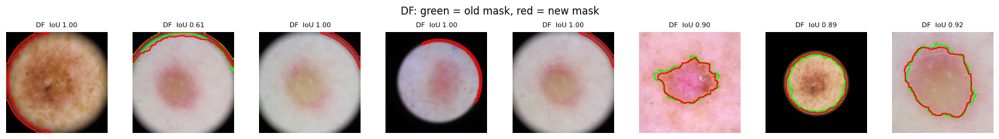

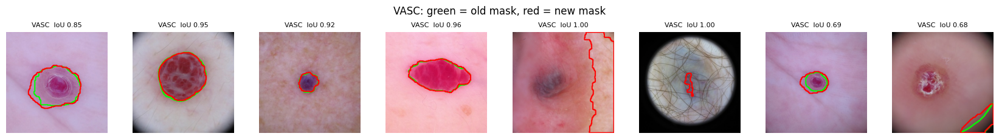

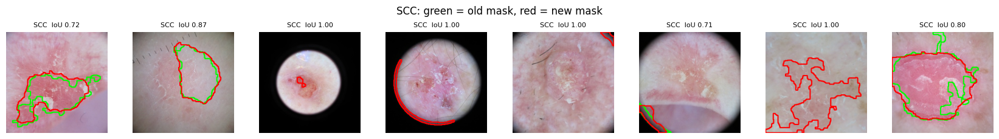

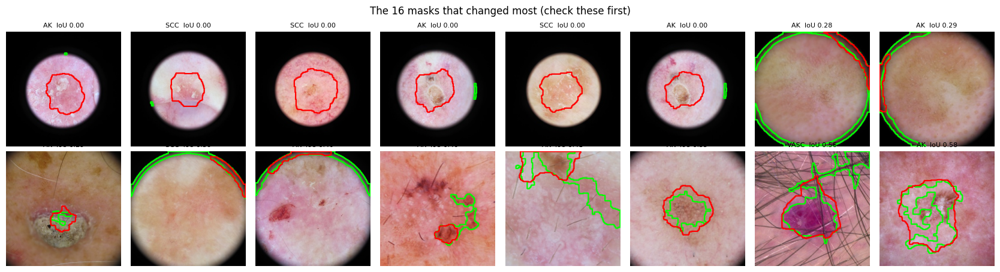

saved masks_v2_tail_L.npz and mask_refinement_stats.csv


In [ ]:
# ---------- E. Better lesion masks: GrabCut refinement of the old masks (tail lesion sources only) ----------
get_mask_old = get_mask                                              # old masks from 5.1 (row i = df.iloc[i])
ell = lambda n: cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (n, n))

def refine_mask(i, iters=6):
    """Start from the old mask, let GrabCut move the boundary onto the real colour edge. Falls back to the old mask if the result looks wrong."""
    im = cv2.imread(str(CACHE_LOCAL / f'{df.image[i]}.jpg')); old = get_mask_old(i).astype(np.uint8); m0 = old.copy()
    valid = cv2.morphologyEx((cv2.cvtColor(im, cv2.COLOR_BGR2GRAY) > 25).astype(np.uint8), cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    if m0.sum() < 200:                                               # old segmentation failed -> start from a central disc
        m0 = np.zeros((S, S), np.uint8); cv2.circle(m0, (S // 2, S // 2), S // 6, 1, -1)
    gc = np.full((S, S), cv2.GC_BGD, np.uint8)
    gc[cv2.dilate(m0, ell(31)) > 0] = cv2.GC_PR_BGD                  # ring around the lesion: probably skin
    gc[m0 > 0] = cv2.GC_PR_FGD                                       # old mask: probably lesion
    gc[cv2.erode(m0, ell(15)) > 0] = cv2.GC_FGD                      # core of the old mask: surely lesion
    gc[valid == 0] = cv2.GC_BGD                                      # black vignette corners: surely not lesion
    if not (gc == cv2.GC_FGD).any(): gc[S // 2 - 4:S // 2 + 4, S // 2 - 4:S // 2 + 4] = cv2.GC_FGD
    try: cv2.grabCut(im, gc, None, np.zeros((1, 65)), np.zeros((1, 65)), iters, cv2.GC_INIT_WITH_MASK)
    except cv2.error: return old
    m = ((gc == cv2.GC_FGD) | (gc == cv2.GC_PR_FGD)).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8)); m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8))
    n, lbl, st, cen = cv2.connectedComponentsWithStats(m)
    if n <= 1: return old
    best, bs = 1, -1
    for c in range(1, n):                                            # biggest component, preferring the centre
        sc = st[c, cv2.CC_STAT_AREA] * (1 - 0.7 * min(np.hypot(cen[c][0] - S / 2, cen[c][1] - S / 2) / (S / 2), 1))
        if sc > bs: bs, best = sc, c
    cnts, _ = cv2.findContours((lbl == best).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    m = np.zeros((S, S), np.uint8); cv2.drawContours(m, cnts, -1, 1, -1)           # fill holes
    touch = (m[:3].sum() + m[-3:].sum() + m[:, :3].sum() + m[:, -3:].sum()) / (4 * 3 * S)
    if not (0.02 <= m.mean() <= 0.65) or touch > 0.15: return old    # sanity check failed -> keep old mask
    return m

# lesion sources of the synthetic generator = labeled (role L) tail images of fold 0
src_idx = np.where((folds[SYN_FOLD]['role'].values == 'L') & df['label'].isin(TAIL_IDX).values)[0]
t0 = time.time(); new = {int(i): refine_mask(int(i)) for i in src_idx}
print(f'refined {len(new)} tail masks in {time.time() - t0:.0f} s')

iou = lambda a, b: float((a & b).sum() / max((a | b).sum(), 1))
cmp = pd.DataFrame([dict(i=i, cls=CLASSES[df.label[i]], iou_old_new=iou(get_mask_old(i).astype(bool), new[i].astype(bool)),
                         area_old=get_mask_old(i).mean(), area_new=new[i].mean(), unchanged=bool((get_mask_old(i) == new[i]).all())) for i in new])
display(cmp.groupby('cls')[['iou_old_new', 'area_old', 'area_new', 'unchanged']].mean().round(3))
print('masks where the sanity check kept the old mask:', int(cmp['unchanged'].sum()), 'of', len(cmp))

def show(ids, title, ncol=8):
    nrow = int(np.ceil(len(ids) / ncol)); fig, axes = plt.subplots(nrow, ncol, figsize=(2.1 * ncol, 2.3 * nrow), squeeze=False)
    for a in axes.ravel(): a.axis('off')
    for a, i in zip(axes.ravel(), ids):
        im = cv2.cvtColor(cv2.imread(str(CACHE_LOCAL / f'{df.image[i]}.jpg')), cv2.COLOR_BGR2RGB)
        for m, col in ((get_mask_old(i), (0, 255, 0)), (new[i], (255, 0, 0))):                 # green = old, red = new
            cnts, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE); cv2.drawContours(im, cnts, -1, col, 2)
        a.imshow(im); a.set_title(f'{CLASSES[df.label[i]]}  IoU {iou(get_mask_old(i).astype(bool), new[i].astype(bool)):.2f}', fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()

rng = np.random.default_rng(0)
for c in TAIL:                                                                                   # random samples per tail class
    ids = cmp[cmp['cls'] == c]['i'].values; show(rng.choice(ids, min(8, len(ids)), replace=False), f'{c}: green = old mask, red = new mask')
show(cmp.sort_values('iou_old_new')['i'].values[:16], 'The 16 masks that changed most (check these first)')

# save (does NOT overwrite the old masks); get_mask_v2 gives new where available, old otherwise
np.savez_compressed(GEN / 'masks_v2_tail_L.npz', idx=np.array(list(new)), packed=np.stack([np.packbits(new[i].ravel()) for i in new]))
cmp.to_csv(REPORT / 'mask_refinement_stats.csv', index=False)
def get_mask_v2(i): return new[i] if i in new else get_mask_old(i)
print('saved masks_v2_tail_L.npz and mask_refinement_stats.csv')

### 5.1c Mask refinement v2: ignore the dark vignette ring, flag masks that are still bad
Green = old mask, red = v2 (usable), yellow = v2 but flagged BAD. Masks flagged BAD should not be used as lesion sources.

refined 187 tail masks in 48 s


status,bad,old_ok,refined,usable,total
cls,,,,,
AK,32,1,62,63,95
DF,3,0,14,14,17
VASC,4,2,22,24,28
SCC,9,0,38,38,47


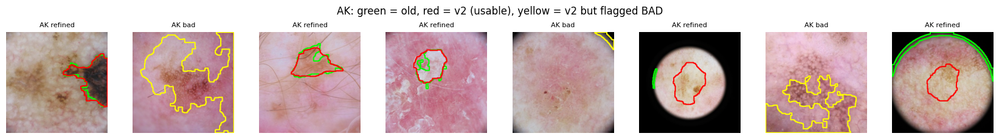

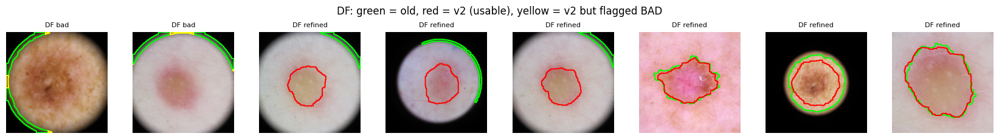

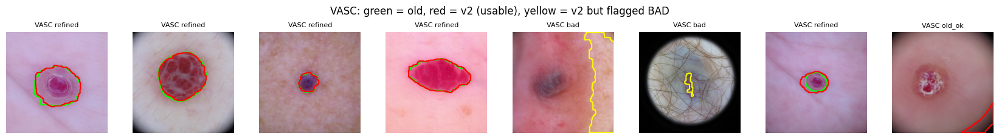

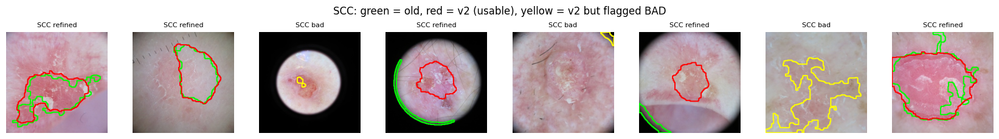

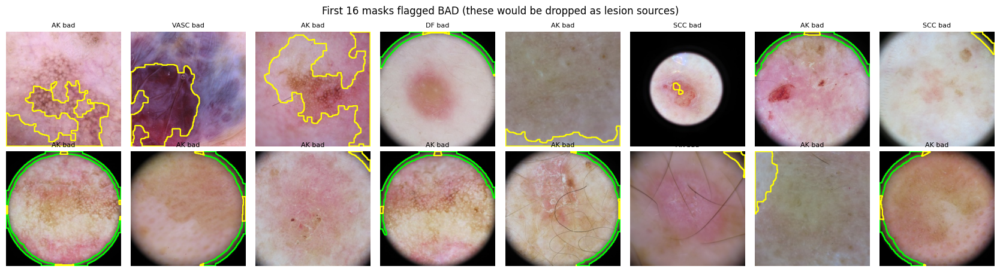

saved 139 usable masks of 187 -> masks_v2b_tail_L.npz (the generator should use only these as lesion sources)


In [ ]:
# ---------- F. Mask refinement v2: ignore the dark vignette ring, flag masks that are still bad ----------
# (run after cell E: it reuses get_mask_old, ell, S, src_idx)
ALLOW_ERODE, EDGE_FRAC_MAX, SOLIDITY_MIN, AREA_MAX = 41, 0.25, 0.60, 0.50      # tune these if the figure shows too many / too few rejections

def field_of_view(im):
    """Region where a lesion can really be: inside the round dermoscope field, 20 px away from its soft dark rim."""
    valid = cv2.morphologyEx((cv2.cvtColor(im, cv2.COLOR_BGR2GRAY) > 25).astype(np.uint8), cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    if valid.mean() > 0.97: return np.ones((S, S), np.uint8)                      # full-frame photo, no black corners
    n, lbl, st, _ = cv2.connectedComponentsWithStats(valid)
    if n <= 1: return np.ones((S, S), np.uint8)
    v = (lbl == 1 + np.argmax(st[1:, cv2.CC_STAT_AREA])).astype(np.uint8)
    a = cv2.erode(v, ell(ALLOW_ERODE))
    return a if a.sum() > 2000 else v

def quality(m, allow):
    """(ok, reason). A mask is bad if it hugs the field rim, is spiky, huge, tiny or touches the image border."""
    a = float(m.mean())
    if not (0.02 <= a <= AREA_MAX): return False, 'area'
    touch = (m[:3].sum() + m[-3:].sum() + m[:, :3].sum() + m[:, -3:].sum()) / (4 * 3 * S)
    if touch > 0.15: return False, 'border'
    din = cv2.distanceTransform(allow, cv2.DIST_L2, 5)
    if (m.astype(bool) & (allow > 0) & (din < 6)).sum() / max(m.sum(), 1) > EDGE_FRAC_MAX: return False, 'rim'
    cnts, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    hull = sum(cv2.contourArea(cv2.convexHull(c)) for c in cnts)
    if hull > 0 and m.sum() / hull < SOLIDITY_MIN: return False, 'spiky'
    return True, 'ok'

def refine_mask2(i, iters=6):
    """returns (mask, status): refined | old_ok | bad (neither the refined nor the old mask is usable -> do not use as lesion source)"""
    im = cv2.imread(str(CACHE_LOCAL / f'{df.image[i]}.jpg')); allow = field_of_view(im)
    old = (get_mask_old(i).astype(np.uint8) * allow); m0 = old.copy()
    if m0.sum() < 200:                                                                        # old mask is a speck -> start from a disc in the middle of the field
        ys, xs = np.where(allow > 0); m0 = np.zeros((S, S), np.uint8); cv2.circle(m0, (int(xs.mean()), int(ys.mean())), S // 6, 1, -1); m0 *= allow
    gc = np.full((S, S), cv2.GC_BGD, np.uint8)
    gc[(cv2.dilate(m0, ell(31)) > 0) & (allow > 0)] = cv2.GC_PR_BGD
    gc[m0 > 0] = cv2.GC_PR_FGD; gc[cv2.erode(m0, ell(15)) > 0] = cv2.GC_FGD; gc[allow == 0] = cv2.GC_BGD
    if not (gc == cv2.GC_FGD).any(): gc[m0 > 0] = cv2.GC_FGD
    try:
        cv2.grabCut(im, gc, None, np.zeros((1, 65)), np.zeros((1, 65)), iters, cv2.GC_INIT_WITH_MASK)
        m = ((gc == cv2.GC_FGD) | (gc == cv2.GC_PR_FGD)).astype(np.uint8) * allow
        m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8)); m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((9, 9), np.uint8))
        n, lbl, st, cen = cv2.connectedComponentsWithStats(m)
        if n > 1:
            sc = [st[c, cv2.CC_STAT_AREA] * (1 - 0.7 * min(np.hypot(cen[c][0] - S / 2, cen[c][1] - S / 2) / (S / 2), 1)) for c in range(1, n)]
            cnts, _ = cv2.findContours((lbl == 1 + int(np.argmax(sc))).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            m = np.zeros((S, S), np.uint8); cv2.drawContours(m, cnts, -1, 1, -1)
            if quality(m, allow)[0]: return m, 'refined'
    except cv2.error: pass
    if old.sum() >= 200 and quality(old, allow)[0]: return old, 'old_ok'
    return old, 'bad'

t0 = time.time(); new2 = {int(i): refine_mask2(int(i)) for i in src_idx}
print(f'refined {len(new2)} tail masks in {time.time() - t0:.0f} s')
st2 = pd.DataFrame([dict(i=i, cls=CLASSES[df.label[i]], status=s, area=float(m.mean())) for i, (m, s) in new2.items()])
tab2 = st2.pivot_table(index='cls', columns='status', values='i', aggfunc='count', fill_value=0).reindex(TAIL)
tab2['usable'] = tab2.get('refined', 0) + tab2.get('old_ok', 0); tab2['total'] = st2.groupby('cls').size().reindex(TAIL)
display(tab2)

def show2(ids, title, ncol=8):
    nrow = int(np.ceil(len(ids) / ncol)); fig, axes = plt.subplots(nrow, ncol, figsize=(2.1 * ncol, 2.3 * nrow), squeeze=False)
    for a in axes.ravel(): a.axis('off')
    for a, i in zip(axes.ravel(), ids):
        im = cv2.cvtColor(cv2.imread(str(CACHE_LOCAL / f'{df.image[i]}.jpg')), cv2.COLOR_BGR2RGB); m, s = new2[i]
        for mm, col in ((get_mask_old(i), (0, 255, 0)), (m, (255, 0, 0) if s != 'bad' else (255, 255, 0))):   # green = old, red = v2, yellow = v2 but BAD
            cnts, _ = cv2.findContours(mm.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE); cv2.drawContours(im, cnts, -1, col, 2)
        a.imshow(im); a.set_title(f'{CLASSES[df.label[i]]} {s}', fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.show()

rng = np.random.default_rng(0)
for c in TAIL:
    ids = [i for i in new2 if CLASSES[df.label[i]] == c]; show2(rng.choice(ids, min(8, len(ids)), replace=False), f'{c}: green = old, red = v2 (usable), yellow = v2 but flagged BAD')
show2([i for i, (m, s) in new2.items() if s == 'bad'][:16], 'First 16 masks flagged BAD (these would be dropped as lesion sources)')

good = np.array([i for i, (m, s) in new2.items() if s != 'bad'])
np.savez_compressed(GEN / 'masks_v2b_tail_L.npz', idx=good, packed=np.stack([np.packbits(new2[i][0].ravel()) for i in good]))
st2.to_csv(REPORT / 'mask_refinement_v2_status.csv', index=False)
def get_mask_v2b(i): return new2[i][0]                                                          # only valid for the indices in `good`
print(f'saved {len(good)} usable masks of {len(new2)} -> masks_v2b_tail_L.npz (the generator should use only these as lesion sources)')

### 5.2 Healthy-skin background bank (lesion removed by inpainting)

background bank: (1500, 256, 256, 3)


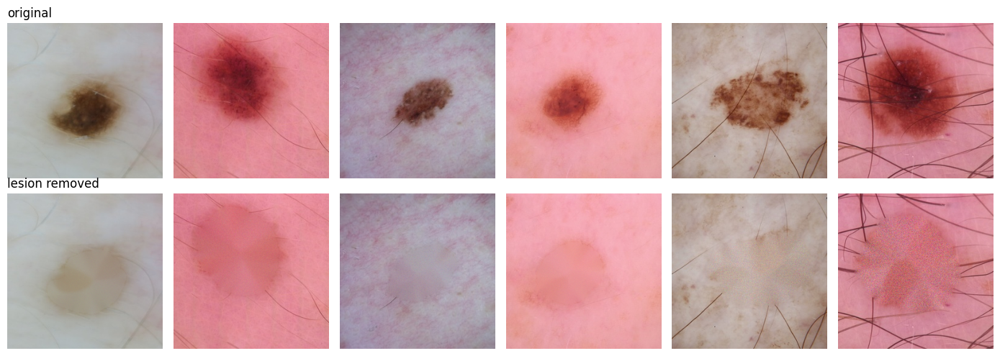

In [ ]:
# ===== PART 2 · CELL 3 · Healthy-skin background bank (lesion removed by inpainting) =====
SYN_FOLD  = 0
N_BG  = 1500
fd_syn    = folds[SYN_FOLD].copy()
GEN_F = GEN / f'fold{SYN_FOLD}'; GEN_F.mkdir(exist_ok=True)
BANK, BANK_IDS = GEN_F / 'bg_bank.npy', GEN_F / 'bg_bank_ids.json'

def clean_skin(i):
    im = cv2.imread(str(CACHE_LOCAL / f'{df.image[i]}.jpg'))
    m  = get_mask(i).astype(np.uint8)
    md = cv2.dilate(m, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (19, 19)))
    out = cv2.inpaint(im, md, 7, cv2.INPAINT_TELEA)
    skin = (md == 0) & (cv2.cvtColor(im, cv2.COLOR_BGR2GRAY) > 25)       # restore skin grain in the filled area
    hp = im.astype(np.float32) - cv2.GaussianBlur(im, (0, 0), 3).astype(np.float32)
    sd = hp[skin].std() if skin.sum() > 100 else 3.0
    noise = np.random.default_rng(i).normal(0, sd, im.shape).astype(np.float32) * cv2.GaussianBlur(md.astype(np.float32), (0, 0), 3)[..., None]
    return cv2.cvtColor(np.clip(out + noise, 0, 255).astype(np.uint8), cv2.COLOR_BGR2RGB)

if BANK.exists():
    bg_bank = np.load(BANK); bg_ids = json.load(open(BANK_IDS))
else:
    ok_train = fd_syn['role'].values != 'test'                              # never use this fold's test images
    cand = np.where(ok_train & df['mask_ok'].values & (df['valid_frac'].values > 0.97) &
                    df['mask_area'].between(0.02, 0.25).values)[0]
    pick = np.random.default_rng(SEED).choice(cand, min(N_BG, len(cand)), replace=False)
    bg_bank = np.stack([clean_skin(i) for i in pick]); bg_ids = [df.image[i] for i in pick]
    np.save(BANK, bg_bank); json.dump(bg_ids, open(BANK_IDS, 'w'))
print('background bank:', bg_bank.shape)

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for j in range(6):
    i = IDX[bg_ids[j]]
    axes[0, j].imshow(Image.open(CACHE_LOCAL / f'{bg_ids[j]}.jpg')); axes[0, j].axis('off')
    axes[1, j].imshow(bg_bank[j]); axes[1, j].axis('off')
axes[0, 0].set_title('original', loc='left'); axes[1, 0].set_title('lesion removed', loc='left')
plt.tight_layout(); plt.show()

### 5.3 Copy-paste generator

lesion sources per class: {'AK': 47, 'DF': 13, 'VASC': 24, 'SCC': 32}
synthetic set already exists: 2400


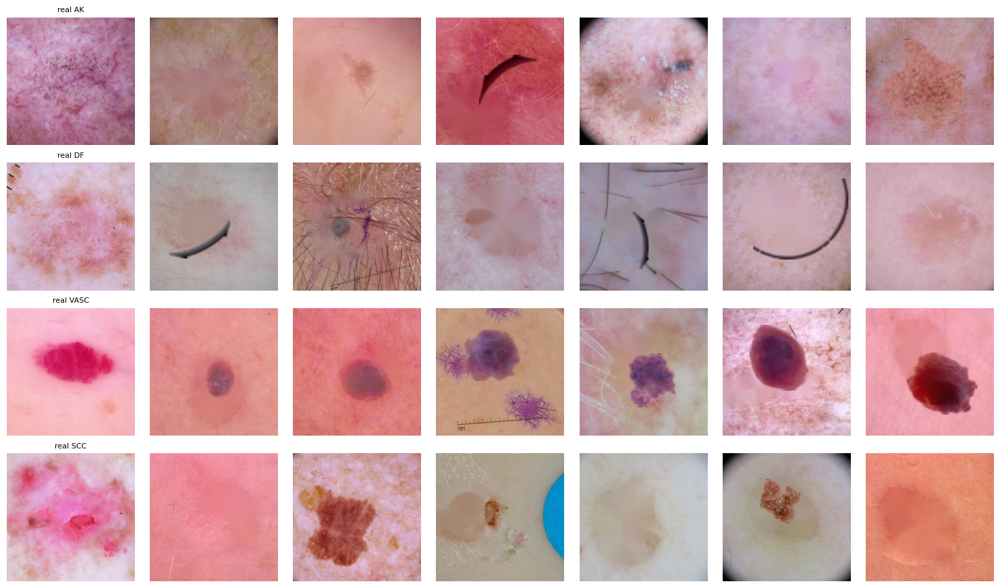

In [ ]:
# ===== PART 2 · CELL 4 · Copy-paste generator =====
def load_rgb(i):
    return cv2.cvtColor(cv2.imread(str(CACHE_LOCAL / f'{i}.jpg')), cv2.COLOR_BGR2RGB)

def make_synth(src_id, bg, rng, p_poisson=0.5):
    """Paste the lesion of `src_id` (random rotation / flip / scale / colour shift) onto skin image `bg`."""
    k = IDX[src_id]; img = load_rgb(src_id); m = get_mask(k).astype(np.uint8)
    ys, xs = np.where(m); y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    patch, pm = img[y0:y1, x0:x1].astype(np.float32), m[y0:y1, x0:x1].astype(np.float32)
    # colour adaptation: move the lesion by 70% of the difference between source skin and target skin
    skin = (cv2.dilate(m, np.ones((25, 25), np.uint8)) == 0) & (img.mean(2) > 25)
    src_skin = np.median(img[skin], axis=0) if skin.sum() > 100 else np.median(img.reshape(-1, 3), axis=0)
    patch = np.clip(patch + 0.7 * (np.median(bg.reshape(-1, 3), axis=0) - src_skin), 0, 255)
    # square canvas, rotate / scale / flip
    h, w = pm.shape; d = int(np.ceil(np.hypot(h, w)))
    P = np.zeros((d, d, 3), np.float32); M = np.zeros((d, d), np.float32)
    oy, ox = (d - h) // 2, (d - w) // 2
    P[oy:oy + h, ox:ox + w] = patch; M[oy:oy + h, ox:ox + w] = pm
    ang, scale = float(rng.uniform(0, 360)), float(rng.uniform(0.8, 1.25))
    A = cv2.getRotationMatrix2D((d / 2, d / 2), ang, scale)
    P = cv2.warpAffine(P, A, (d, d), flags=cv2.INTER_LINEAR); M = cv2.warpAffine(M, A, (d, d), flags=cv2.INTER_LINEAR)
    if rng.random() < 0.5: P, M = P[:, ::-1], M[:, ::-1]
    # mild brightness / contrast jitter
    P = np.clip((P - 128) * rng.uniform(0.9, 1.1) + 128 + rng.uniform(-10, 10), 0, 255)
    ys, xs = np.where(M > 0.5)
    if len(ys) < 50: return None
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    P, M = P[y0:y1, x0:x1], M[y0:y1, x0:x1]
    f = min(1.0, 190 / max(P.shape[:2]))
    if f < 1: P, M = cv2.resize(P, None, fx=f, fy=f), cv2.resize(M, None, fx=f, fy=f)
    ph, pw = M.shape; P8 = P.astype(np.uint8)
    cx = int(np.clip(S // 2 + rng.integers(-35, 36), pw // 2 + 2, S - pw // 2 - 2))
    cy = int(np.clip(S // 2 + rng.integers(-35, 36), ph // 2 + 2, S - ph // 2 - 2))
    alpha = cv2.GaussianBlur(M, (0, 0), 1.5)[..., None]
    top, left = cy - ph // 2, cx - pw // 2
    blend = 'poisson' if rng.random() < p_poisson else 'alpha'
    out = bg.copy()
    if blend == 'poisson':
        try:
            mask8 = np.pad((M > 0.5).astype(np.uint8) * 255, 1)[1:-1, 1:-1]
            out = cv2.seamlessClone(P8, bg, mask8, (left + pw // 2, top + ph // 2), cv2.NORMAL_CLONE)
        except cv2.error:
            blend = 'alpha'
    if blend == 'alpha':
        reg = out[top:top + ph, left:left + pw].astype(np.float32)
        out[top:top + ph, left:left + pw] = (alpha * P8 + (1 - alpha) * reg).astype(np.uint8)
    newmask = np.zeros((S, S), np.uint8); newmask[top:top + ph, left:left + pw] = (M > 0.5)
    return out, newmask, dict(angle=round(ang, 1), scale=round(scale, 3), blend=blend, cx=cx, cy=cy)

# ---------------- generate ----------------
N_SYN   = {'AK': 600, 'DF': 600, 'VASC': 600, 'SCC': 600}      # synthetic images per tail class
SYN_TAG = 'cp_v1'
SYN_DIR = Path('/content/synth') / f'fold{SYN_FOLD}_{SYN_TAG}'; SYN_DIR.mkdir(parents=True, exist_ok=True)
SYN_ZIP = GEN_F / f'synth_{SYN_TAG}.zip'; SYN_MAN = GEN_F / f'synth_{SYN_TAG}_manifest.csv'

# lesion sources = labeled tail images of D_L only (meta and test are never used, U needs pseudo-labels, later)
src = df[(fd_syn['role'].values == 'L') & df['cls'].isin(TAIL).values & df['mask_ok'].values]
print('lesion sources per class:', src['cls'].value_counts().reindex(TAIL).to_dict())

if SYN_MAN.exists():
    syn = pd.read_csv(SYN_MAN)
    if not (SYN_DIR / syn['file'].iloc[0]).exists() and SYN_ZIP.exists():
        with zipfile.ZipFile(SYN_ZIP) as z: z.extractall(SYN_DIR)
    print('synthetic set already exists:', len(syn))
else:
    rows, n = [], 0
    for c in TAIL:
        pool_c = src.index[src['cls'] == c].tolist()
        for j in range(N_SYN[c]):
            rng = np.random.default_rng(SEED * 100000 + n); n += 1
            for _ in range(5):                                     # retry on rare failures
                sid = df.image[pool_c[rng.integers(len(pool_c))]]; b = int(rng.integers(len(bg_bank)))
                r = make_synth(sid, bg_bank[b], rng)
                if r is not None: break
            out, nm, info = r
            fn = f'{c}_{j:04d}.jpg'
            cv2.imwrite(str(SYN_DIR / fn), cv2.cvtColor(out, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_JPEG_QUALITY, 95])
            rows.append(dict(file=fn, cls=c, label=C2I[c], src=sid, bg=bg_ids[b], **info))
    syn = pd.DataFrame(rows); syn.to_csv(SYN_MAN, index=False)
    with zipfile.ZipFile(SYN_ZIP, 'w', zipfile.ZIP_STORED) as z:
        for f in syn['file']: z.write(SYN_DIR / f, f)
    print('generated', len(syn), 'images ->', SYN_ZIP.name)

# ---------------- preview ----------------
fig, axes = plt.subplots(len(TAIL), 7, figsize=(15, 2.2 * len(TAIL)))
for r, c in enumerate(TAIL):
    real = src[src.cls == c].image.values[0]
    axes[r, 0].imshow(load_rgb(real)); axes[r, 0].set_title(f'real {c}', fontsize=8); axes[r, 0].axis('off')
    for j, fn in enumerate(syn[syn.cls == c].file.values[:6]):
        axes[r, j + 1].imshow(Image.open(SYN_DIR / fn)); axes[r, j + 1].axis('off')
plt.tight_layout(); plt.show()

### 5.4 DINOv2 embeddings and the quality feature Q
Q measures how close a synthetic image is to *real* labeled images of its class (from D_L only). Embeddings are saved, so DINOv2 is only loaded when they are missing.

In [ ]:
_dino = None
def get_dino():
    global _dino
    if _dino is None:
        from transformers import AutoModel
        m = AutoModel.from_pretrained('facebook/dinov2-small').to(dev).eval()
        _dino = m.half() if dev == 'cuda' else m
    return _dino

@torch.no_grad()
def embed(paths, bs=64):
    dino = get_dino()
    mean = torch.tensor([0.485, 0.456, 0.406], device=dev).view(1, 3, 1, 1); std = torch.tensor([0.229, 0.224, 0.225], device=dev).view(1, 3, 1, 1)
    out = []
    for i in range(0, len(paths), bs):
        x = np.stack([cv2.resize(np.array(Image.open(p).convert('RGB')), (224, 224)) for p in paths[i:i + bs]])
        x = torch.from_numpy(x).to(dev).permute(0, 3, 1, 2).float() / 255
        e = dino(pixel_values=((x - mean) / std).to(dino.dtype)).last_hidden_state[:, 0].float()
        out.append(torch.nn.functional.normalize(e, dim=1).cpu())
    return torch.cat(out).numpy()

EMB_SYN, EMB_REAL = GEN_F / f'emb_synth_{SYN_TAG}.npy', GEN_F / 'emb_real_L_meta_tail.npy'
real_tab = df[(fd_syn['role'].isin(['L', 'meta']).values) & df['cls'].isin(TAIL).values].copy()
real_tab['role'] = fd_syn.loc[real_tab.index, 'role'].values
if EMB_SYN.exists() and EMB_REAL.exists():
    e_syn, e_real = np.load(EMB_SYN), np.load(EMB_REAL)
else:
    e_syn  = embed([str(SYN_DIR / f) for f in syn['file']])
    e_real = embed([str(CACHE_LOCAL / f'{i}.jpg') for i in real_tab['image']])
    np.save(EMB_SYN, e_syn); np.save(EMB_REAL, e_real)

Q_proto, Q_nn = np.zeros(len(syn)), np.zeros(len(syn))
for c in TAIL:
    refL = e_real[((real_tab['cls'] == c) & (real_tab['role'] == 'L')).values]
    proto = refL.mean(0); proto /= np.linalg.norm(proto)
    ii = np.where(syn['cls'] == c)[0]
    Q_proto[ii] = e_syn[ii] @ proto; Q_nn[ii] = (e_syn[ii] @ refL.T).max(1)
syn['Q_proto'], syn['Q_nn'] = Q_proto, Q_nn
syn.to_csv(GEN_F / f'synth_{SYN_TAG}_feats.csv', index=False)

rows = []
for c in TAIL:                                       # sanity: real held-out (meta) images should score at least as high as synthetic ones
    refL = e_real[((real_tab['cls'] == c) & (real_tab['role'] == 'L')).values]
    proto = refL.mean(0); proto /= np.linalg.norm(proto)
    em = e_real[((real_tab['cls'] == c) & (real_tab['role'] == 'meta')).values]
    rows.append(dict(cls=c, n_L=len(refL), n_meta=len(em), Q_proto_synth=Q_proto[syn['cls'] == c].mean(), Q_proto_real_meta=(em @ proto).mean()))
display(pd.DataFrame(rows).round(3))

,cls,n_L,n_meta,Q_proto_synth,Q_proto_real_meta
0,AK,95,58,0.641,0.783
1,DF,17,8,0.651,0.729
2,VASC,28,7,0.686,0.779
3,SCC,47,17,0.672,0.750


## 6. Training tools
One model (EfficientNet-B0), one metric function and **one generic runner** for all loss variants. Training images are read from the local disk batch by batch, so memory stays low (an earlier version that kept every image in RAM crashed Colab on the pseudo-label runs).

Losses: `ce` plain; `wce` class-weighted; `focal` (gamma 2); `la` logit adjustment (log class prior added to the logits *before* the softmax, prior from all training data); `la_real` logit adjustment with the prior of the **real** labeled set only (used when synthetic images are added); `la_pl` logit adjustment for the pseudo-label model. Evaluation always uses the plain logits.

BMA = balanced multi-class accuracy (mean per-class recall). The best epoch is chosen on the meta set; the test fold is only used for the final numbers.

In [ ]:
import psutil
import torch.nn as nn, torch.nn.functional as F, torchvision
from torchvision.transforms import v2
from torch.utils.data import Dataset, DataLoader
from multiprocessing.pool import ThreadPool
from sklearn.metrics import balanced_accuracy_score, f1_score, recall_score, accuracy_score, confusion_matrix

assert dev == 'cuda', 'Switch the runtime to a GPU first (Runtime > Change runtime type)'
ram = lambda: f'RAM {psutil.virtual_memory().used/1e9:.1f}/{psutil.virtual_memory().total/1e9:.1f} GB'

def _read(p): return torch.from_numpy(cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)).permute(2, 0, 1)
def _fill(buf, i, p): buf[i] = _read(p)
def load_tensor(paths):
    buf = torch.empty((len(paths), 3, IMG_SIZE, IMG_SIZE), dtype=torch.uint8)
    with ThreadPool(8) as p: p.starmap(_fill, [(buf, i, q) for i, q in enumerate(paths)])
    return buf

MEAN_, STD_ = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
tf_train = v2.Compose([v2.RandomResizedCrop(TCFG['crop'], scale=(0.6, 1.0), antialias=True), v2.RandomHorizontalFlip(),
                       v2.RandomVerticalFlip(), v2.ColorJitter(0.15, 0.15, 0.1), v2.ToDtype(torch.float32, scale=True), v2.Normalize(MEAN_, STD_)])
tf_eval  = v2.Compose([v2.Resize(TCFG['crop'], antialias=True), v2.ToDtype(torch.float32, scale=True), v2.Normalize(MEAN_, STD_)])

class DSlazy(Dataset):
    """Reads each jpg from local disk on demand. Returns (image, label, weight, index)."""
    def __init__(s, paths, y, w=None): s.p, s.y, s.w = paths, y, (torch.ones(len(paths)) if w is None else w)
    def __len__(s): return len(s.p)
    def __getitem__(s, i): return tf_train(_read(s.p[i])), s.y[i], s.w[i], i

def make_model():
    m = torchvision.models.efficientnet_b0(weights='IMAGENET1K_V1')
    m.classifier[1] = nn.Linear(m.classifier[1].in_features, K); return m.to(dev)

@torch.no_grad()
def predict(model, x, bs=256):
    model.eval(); out = []
    for i in range(0, len(x), bs):
        with torch.autocast('cuda', dtype=torch.float16): out.append(model(tf_eval(x[i:i + bs].to(dev))).float().cpu())
    return torch.cat(out)                                                  # logits

def predict_paths(model, paths, chunk=1024):
    return torch.cat([predict(model, load_tensor(paths[i:i + chunk])) for i in range(0, len(paths), chunk)])

def metrics(logits, y):
    p, y = logits.argmax(1).numpy(), y.numpy(); lab = list(range(K))
    rec = recall_score(y, p, labels=lab, average=None, zero_division=0)
    return dict(bma=float(balanced_accuracy_score(y, p)), macro_f1=float(f1_score(y, p, labels=lab, average='macro', zero_division=0)),
                acc=float(accuracy_score(y, p)), tail_recall=float(rec[TAIL_IDX].mean()), recall={c: float(r) for c, r in zip(CLASSES, rec)})

# ---------------- fold state ----------------
def setup_fold(k):
    """Load the evaluation tensors (meta, test) and tables of fold k into the globals used by all runners."""
    global FOLD, fd, tabs, X, Y, RUN_DIR, tabU, YU
    FOLD = k; fd = folds[k]; RUN_DIR = RUNS / f'fold{k}'; RUN_DIR.mkdir(parents=True, exist_ok=True)
    X, Y = {}, {}; gc.collect()
    tabs = {r: df[fd['role'].values == r].reset_index(drop=True) for r in ['L', 'meta', 'test']}
    Y = {r: torch.tensor(t['label'].values) for r, t in tabs.items()}
    X = {r: load_tensor([CACHE_LOCAL / f'{i}.jpg' for i in tabs[r]['image']]) for r in ['meta', 'test']}
    tabU = df[fd['role'].values == 'U'].reset_index(drop=True); YU = tabU['label'].values     # YU: only to SCORE pseudo-labels
    print(f'fold {k}: L {len(Y["L"])} | meta {len(Y["meta"])} | test {len(Y["test"])} | unlabeled {len(tabU)} | {ram()}')

# ---------------- generic runner ----------------
def fit_std(paths, yt, wt, cw, log_prior, focal=False):
    """Train on `paths`; returns the model with the best-meta-BMA weights."""
    loader = DataLoader(DSlazy(paths, yt, wt), batch_size=TCFG['bs'], shuffle=True, num_workers=2, drop_last=True)
    model = make_model(); opt = torch.optim.AdamW(model.parameters(), lr=TCFG['lr'], weight_decay=TCFG['wd'])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=TCFG['epochs'] * len(loader)); scaler = torch.amp.GradScaler('cuda')
    best, best_state, hist = -1, None, []
    for ep in range(TCFG['epochs']):
        model.train(); tl = 0
        for xb, yb, wb, _ in loader:
            xb, yb, wb = xb.to(dev), yb.to(dev), wb.to(dev)
            with torch.autocast('cuda', dtype=torch.float16): out = model(xb)
            out = out.float() + (0 if log_prior is None else log_prior)       # logit adjustment happens BEFORE the softmax
            ce = F.cross_entropy(out, yb, reduction='none')
            if focal: ce = ce * (1 - torch.exp(-ce)) ** 2
            l = (ce * cw[yb] * wb).mean()
            opt.zero_grad(set_to_none=True); scaler.scale(l).backward(); scaler.step(opt); scaler.update(); sched.step(); tl += l.item()
        mm = metrics(predict(model, X['meta']), Y['meta'])
        hist.append(dict(epoch=ep, loss=tl / len(loader), meta_bma=mm['bma'], meta_tail_recall=mm['tail_recall']))
        if mm['bma'] > best: best, best_ep, best_state = mm['bma'], ep, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_state); del loader, opt
    return model, best_state, best_ep, hist

def finish(name, d, rf, cfg, model, best_state, best_ep, hist, t0, extra=None):
    lt, lm = predict(model, X['test']), predict(model, X['meta'])
    torch.save(best_state, d / 'best.pt'); np.save(d / 'test_logits.npy', lt.numpy())
    r = dict(cfg=cfg, best_epoch=best_ep, meta=metrics(lm, Y['meta']), test=metrics(lt, Y['test']), hist=hist, minutes=round((time.time() - t0) / 60, 1))
    if extra: r.update(extra)
    json.dump(r, open(rf, 'w'), indent=1)
    print(f'{name}: test BMA {r["test"]["bma"]:.3f}  tail-recall {r["test"]["tail_recall"]:.3f}  ({r["minutes"]} min) | {ram()}')
    del model; gc.collect(); torch.cuda.empty_cache(); return r

def load_done(name, rf, cfg):
    r = json.load(open(rf)); assert r['cfg'] == cfg, f'{name}: the saved run used other settings: {r["cfg"]}'
    print(name, '-> already done, loaded'); return r

def run_std(name, loss='ce', use_synth=False, synth_w=None):
    """Train on D_L (+ synthetic images). loss in ce | wce | focal | la | la_real."""
    assert loss in ('ce', 'wce', 'focal', 'la', 'la_real')
    d = RUN_DIR / name; d.mkdir(exist_ok=True); rf = d / 'result.json'
    cfg = dict(TCFG, loss=loss, use_synth=use_synth, synth_w=None if synth_w is None else round(float(np.sum(synth_w)), 3))
    if rf.exists(): return load_done(name, rf, cfg)
    torch.manual_seed(SEED); np.random.seed(SEED); t0 = time.time()
    paths = [CACHE_LOCAL / f'{i}.jpg' for i in tabs['L']['image']]; yt = Y['L']; wt = torch.ones(len(yt))
    if use_synth:
        paths += [SYN_DIR / f for f in syn['file']]
        yt = torch.cat([yt, torch.tensor(syn['label'].values)])
        wt = torch.cat([wt, torch.as_tensor(np.ones(len(syn)) if synth_w is None else synth_w, dtype=torch.float32)])
    cnt, cntL = torch.bincount(yt, minlength=K).float(), torch.bincount(Y['L'], minlength=K).float()
    cw, log_prior = torch.ones(K), None
    if loss == 'wce': cw = cnt.sum() / (K * cnt.clamp(min=1))
    if loss == 'la': log_prior = torch.log(cnt / cnt.sum()).to(dev)
    if loss == 'la_real': log_prior = torch.log(cntL / cntL.sum()).to(dev)           # real prior only
    model, bs_, be, hist = fit_std(paths, yt, wt, cw.to(dev), log_prior, focal=(loss == 'focal'))
    return finish(name, d, rf, cfg, model, bs_, be, hist, t0)

# ---------------- seeds, registry, reporting helpers ----------------
def rname(m, s): return m if s == 42 else f'{m}_s{s}'
def with_seed(s, fn, *a, **k):
    """Run fn with the global SEED (and TCFG['seed']) temporarily set to s."""
    global SEED
    old = SEED; SEED = s; TCFG['seed'] = s
    try: return fn(*a, **k)
    finally: SEED = old; TCFG['seed'] = old

RES = {}                                                          # RES[method][seed] -> result dict (fold SYN_FOLD)
def run_method(m, fn, seeds=None, **kw):
    RES.setdefault(m, {})
    for s in (SEEDS if seeds is None else seeds): RES[m][s] = with_seed(s, fn, rname(m, s), **kw)
    return RES[m]

def agg_table(methods):
    rows = []
    for m in methods:
        t = [RES[m][s]['test'] for s in sorted(RES[m])]
        rows.append(dict(method=m, n_seeds=len(t), BMA=np.mean([x['bma'] for x in t]), BMA_sd=np.std([x['bma'] for x in t]),
                         F1=np.mean([x['macro_f1'] for x in t]), tail_recall=np.mean([x['tail_recall'] for x in t]),
                         **{f'R_{c}': np.mean([x['recall'][c] for x in t]) for c in CLASSES}))
    return pd.DataFrame(rows).set_index('method').round(3)

def paired(a, b, key='bma'):
    ss = [s for s in SEEDS if s in RES[a] and s in RES[b]]
    d = np.array([RES[a][s]['test'][key] - RES[b][s]['test'][key] for s in ss])
    print(f'{a} minus {b}: {key} mean {d.mean():+.3f}  per seed {np.round(d, 3)}'); return d

setup_fold(SYN_FOLD)

fold 0: L 2012 | meta 1058 | test 5004 | unlabeled 17257 | RAM 5.2/13.6 GB


## 7. Baselines on D_L only (fold 0, 3 seeds)
Plain cross-entropy, class-weighted cross-entropy, focal loss and logit adjustment. Every later method has to beat the best of these.

ce_L -> already done, loaded
ce_L_s1 -> already done, loaded
ce_L_s2 -> already done, loaded
wce_L -> already done, loaded
wce_L_s1 -> already done, loaded
wce_L_s2 -> already done, loaded
focal_L -> already done, loaded
focal_L_s1 -> already done, loaded
focal_L_s2 -> already done, loaded
la_L -> already done, loaded
la_L_s1 -> already done, loaded
la_L_s2 -> already done, loaded


,n_seeds,BMA,BMA_sd,F1,tail_recall,R_MEL,R_NV,R_BCC,R_AK,R_BKL,R_DF,R_VASC,R_SCC
method,,,,,,,,,,,,,
ce_L,3,0.439,0.005,0.450,0.228,0.572,0.837,0.758,0.281,0.428,0.006,0.469,0.157
wce_L,3,0.462,0.006,0.455,0.297,0.573,0.777,0.695,0.307,0.466,0.063,0.592,0.226
focal_L,3,0.441,0.003,0.454,0.234,0.552,0.850,0.756,0.294,0.431,0.006,0.491,0.145
la_L,3,0.496,0.014,0.445,0.379,0.573,0.750,0.677,0.333,0.452,0.333,0.645,0.206


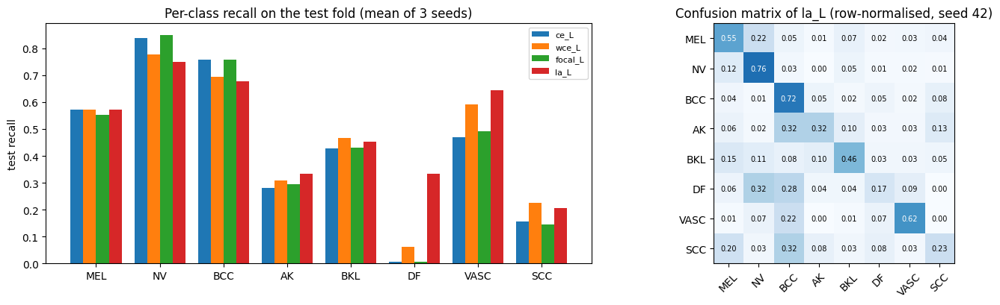

In [ ]:
for m, kw in [('ce_L', dict(loss='ce')), ('wce_L', dict(loss='wce')), ('focal_L', dict(loss='focal')), ('la_L', dict(loss='la'))]:
    run_method(m, run_std, **kw)
BASE = ['ce_L', 'wce_L', 'focal_L', 'la_L']
display(agg_table(BASE))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.2)); w = 0.8 / len(BASE)
for k, m in enumerate(BASE):
    ax[0].bar(np.arange(K) + k * w, [np.mean([RES[m][s]['test']['recall'][c] for s in SEEDS]) for c in CLASSES], w, label=m)
ax[0].set_xticks(np.arange(K) + 0.4 - w / 2); ax[0].set_xticklabels(CLASSES); ax[0].set_ylabel('test recall'); ax[0].legend(fontsize=8)
ax[0].set_title('Per-class recall on the test fold (mean of 3 seeds)')
cm = confusion_matrix(Y['test'].numpy(), np.load(RUN_DIR / 'la_L' / 'test_logits.npy').argmax(1), labels=range(K), normalize='true')
ax[1].imshow(cm, cmap='Blues', vmin=0, vmax=1); ax[1].set_xticks(range(K)); ax[1].set_yticks(range(K))
ax[1].set_xticklabels(CLASSES, rotation=45); ax[1].set_yticklabels(CLASSES)
for i in range(K):
    for j in range(K): ax[1].text(j, i, f'{cm[i, j]:.2f}', ha='center', va='center', fontsize=7, color='white' if cm[i, j] > .5 else 'black')
ax[1].set_title('Confusion matrix of la_L (row-normalised, seed 42)'); plt.tight_layout(); plt.show()

## 8. Reliability features for every synthetic image
Q (quality, from section 5.4), **C** (the baseline classifier's confidence in the target class), **D** (Mahalanobis distance to the class in DINOv2 space, pooled covariance), **U** (normalised entropy). C and U come from the `ce_L` baseline. The table compares each feature on synthetic images with real held-out (meta) tail images.

features loaded from Drive


,Q_nn_synth,C_synth,D_synth,U_synth
cls,,,,
AK,0.690,0.090,32.140,0.365
DF,0.672,0.057,30.382,0.417
VASC,0.693,0.380,31.539,0.371
SCC,0.702,0.111,29.901,0.344


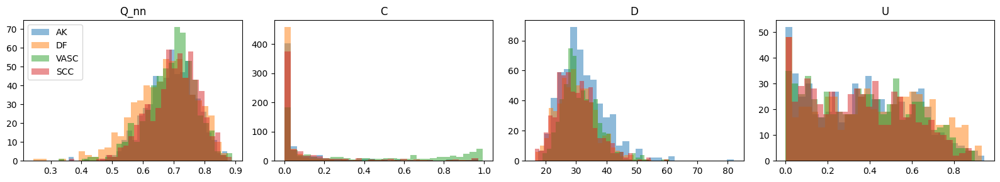

In [ ]:
from sklearn.covariance import LedoitWolf
FEAT_CSV = GEN_F / f'synth_{SYN_TAG}_features.csv'
if FEAT_CSV.exists():
    feat = pd.read_csv(FEAT_CSV); print('features loaded from Drive')
else:
    base = make_model(); base.load_state_dict(torch.load(RUN_DIR / 'ce_L' / 'best.pt'))
    logit_syn = predict_paths(base, [SYN_DIR / f for f in syn['file']]); logit_meta = predict(base, X['meta'])
    def conf_unc(logits, y):
        p = logits.softmax(1)
        return p[torch.arange(len(y)), y].numpy(), (-(p * p.clamp_min(1e-9).log()).sum(1) / np.log(K)).numpy()
    C_syn, U_syn = conf_unc(logit_syn, torch.tensor(syn['label'].values))
    e_L = embed([str(CACHE_LOCAL / f'{i}.jpg') for i in tabs['L']['image']]); yL = Y['L'].numpy()
    means = np.stack([e_L[yL == k].mean(0) for k in range(K)])
    P = LedoitWolf().fit(e_L - means[yL]).precision_
    maha = lambda e, y: np.sqrt(np.einsum('ij,jk,ik->i', e - means[y], P, e - means[y]))
    feat = syn[['file', 'cls', 'label', 'Q_proto', 'Q_nn']].copy()
    feat['C'], feat['U'], feat['D'] = C_syn, U_syn, maha(e_syn, syn['label'].values)
    feat.to_csv(FEAT_CSV, index=False)
    mt = np.isin(Y['meta'].numpy(), TAIL_IDX); Cm, Um = conf_unc(logit_meta[mt], Y['meta'][mt])
    ym = Y['meta'].numpy()[mt]; Dm = maha(e_real[(real_tab['role'] == 'meta').values], ym)
    real_ref = pd.DataFrame([dict(cls=c, C_real_meta=Cm[ym == C2I[c]].mean(), U_real_meta=Um[ym == C2I[c]].mean(),
                                  D_real_meta=Dm[ym == C2I[c]].mean()) for c in TAIL]).set_index('cls')
    display(real_ref.round(3)); del base
assert (feat['file'].values == syn['file'].values).all(), 'feature table and synthetic manifest are out of order'
display(feat.groupby('cls')[FEATS].mean().reindex(TAIL).round(3).rename(columns=lambda c: c + '_synth'))
fig, ax = plt.subplots(1, 4, figsize=(16, 3))
for a, col in zip(ax, FEATS):
    for c in TAIL: a.hist(feat.loc[feat.cls == c, col], bins=30, alpha=.5, label=c)
    a.set_title(col)
ax[0].legend(); plt.tight_layout(); plt.show()

## 9. Synthetic images at fixed weights, and a real-vs-fake probe
Synthetic images are added to D_L at weight 1 (or 0.3). With logit adjustment, the **real** prior (`la_real`) is used, because adding 2,400 synthetic tail images would otherwise inflate the tail prior and cancel the adjustment. Then a probe checks whether a linear classifier on DINOv2 features can tell synthetic images from real held-out tail images (AUC near 1 means the pasted images carry detectable artifacts, a possible shortcut).

In [ ]:
STATIC = {'ce_L_synth_w1':      dict(loss='ce',      use_synth=True),
          'wce_L_synth_w1':     dict(loss='wce',     use_synth=True),
          'la_L_synth_w1':      dict(loss='la',      use_synth=True),      # prior includes the synthetic counts (confounded, kept for the record)
          'la_real_synth_w1':   dict(loss='la_real', use_synth=True),
          'la_real_synth_w03':  dict(loss='la_real', use_synth=True, synth_w=np.full(len(syn), 0.3))}
for m, kw in STATIC.items(): run_method(m, run_std, **kw)
display(agg_table(['la_L'] + list(STATIC)))
for a in ['la_real_synth_w1', 'la_real_synth_w03', 'la_L_synth_w1']: paired(a, 'la_L')

# ---- probe: real held-out (meta) tail images vs synthetic images ----
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import roc_auc_score
is_meta = (real_tab['role'] == 'meta').values
e_r, c_r = e_real[is_meta], real_tab['cls'].values[is_meta]
Xe = np.vstack([e_r, e_syn]); yd = np.r_[np.zeros(len(e_r)), np.ones(len(e_syn))]; cls_all = np.r_[c_r, syn['cls'].values]
pr = cross_val_predict(LogisticRegression(max_iter=3000, class_weight='balanced'), Xe, yd,
                       cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method='predict_proba')[:, 1]
print(f'\nreal vs synthetic probe, all tail classes: AUC = {roc_auc_score(yd, pr):.3f}  ({len(e_r)} real, {len(e_syn)} synthetic)')
for c in TAIL:
    m_ = cls_all == c; print(f'  {c}: AUC = {roc_auc_score(yd[m_], pr[m_]):.3f}  (real {int((yd[m_] == 0).sum())})')

ce_L_synth_w1 -> already done, loaded
ce_L_synth_w1_s1 -> already done, loaded
ce_L_synth_w1_s2 -> already done, loaded
wce_L_synth_w1 -> already done, loaded
wce_L_synth_w1_s1 -> already done, loaded
wce_L_synth_w1_s2 -> already done, loaded
la_L_synth_w1 -> already done, loaded
la_L_synth_w1_s1 -> already done, loaded
la_L_synth_w1_s2 -> already done, loaded
la_real_synth_w1 -> already done, loaded
la_real_synth_w1_s1 -> already done, loaded
la_real_synth_w1_s2 -> already done, loaded
la_real_synth_w03 -> already done, loaded
la_real_synth_w03_s1 -> already done, loaded
la_real_synth_w03_s2 -> already done, loaded


,n_seeds,BMA,BMA_sd,F1,tail_recall,R_MEL,R_NV,R_BCC,R_AK,R_BKL,R_DF,R_VASC,R_SCC
method,,,,,,,,,,,,,
la_L,3,0.496,0.014,0.445,0.379,0.573,0.750,0.677,0.333,0.452,0.333,0.645,0.206
ce_L_synth_w1,3,0.435,0.009,0.442,0.267,0.465,0.860,0.669,0.424,0.417,0.069,0.487,0.087
wce_L_synth_w1,3,0.445,0.009,0.452,0.227,0.622,0.794,0.721,0.221,0.514,0.075,0.531,0.081
la_L_synth_w1,3,0.450,0.012,0.458,0.238,0.572,0.808,0.748,0.247,0.519,0.088,0.531,0.087
la_real_synth_w1,3,0.478,0.008,0.438,0.339,0.526,0.784,0.659,0.381,0.497,0.226,0.667,0.081
la_real_synth_w03,3,0.498,0.008,0.445,0.397,0.516,0.779,0.635,0.420,0.466,0.327,0.697,0.145


la_real_synth_w1 minus la_L: bma mean -0.018  per seed [-0.01  -0.024 -0.021]
la_real_synth_w03 minus la_L: bma mean +0.002  per seed [ 0.023 -0.002 -0.015]
la_L_synth_w1 minus la_L: bma mean -0.046  per seed [-0.037 -0.041 -0.061]

real vs synthetic probe, all tail classes: AUC = 0.988  (90 real, 2400 synthetic)
  AK: AUC = 0.991  (real 58)
  DF: AUC = 0.978  (real 8)
  VASC: AUC = 0.966  (real 7)
  SCC: AUC = 0.990  (real 17)


## 10. Learned reliability filter (bi-level optimisation)
The filter gives every synthetic image a weight **R = sigmoid(w · features + b)** (4 weights and a bias; features are z-scored within each class; it starts at R = 0.5). Gradients cannot flow through pasted pixels, so R only weights the loss, which makes the weights differentiable. Each meta step:

1. virtual step on the classifier head with the R-weighted loss, `W' = W - alpha * grad`;
2. loss of `W'` on a **class-balanced batch of real meta images**;
3. update the filter parameters from that loss (Adam).

The backbone and head are then trained normally with the detached weights. Only the head is differentiated through (a deliberate simplification of the original design). Filters are trained on top of `ce`, `wce` and `la_real`. **Controls** retrain from scratch with fixed weights: the learned ones, the same values shuffled within each class, and a constant 0.5. If the learned weights beat both controls, the *choice* of images matters.

In [ ]:
Fm = feat[FEATS].copy()
for c in TAIL:                                    # z-score within each class: the filter ranks images inside a class
    m_ = (feat['cls'] == c).values
    Fm.loc[m_, FEATS] = (Fm.loc[m_, FEATS] - Fm.loc[m_, FEATS].mean()) / (Fm.loc[m_, FEATS].std() + 1e-6)
F_syn = torch.tensor(Fm.values, dtype=torch.float32, device=dev)

class GFilter(nn.Module):
    def __init__(s, n=len(FEATS)):
        super().__init__(); s.w = nn.Parameter(torch.zeros(n)); s.b = nn.Parameter(torch.zeros(1))
    def forward(s, f): return torch.sigmoid(f @ s.w + s.b)

def run_bilevel(name, loss='ce'):
    """loss in ce | wce | la_real. The filter is trained jointly with the classifier on D_L + all synthetic images."""
    assert loss in ('ce', 'wce', 'la_real')
    d = RUN_DIR / name; d.mkdir(exist_ok=True); rf = d / 'result.json'
    cfg = dict(TCFG, loss=loss, bilevel=BCFG, feats=FEATS)
    if rf.exists(): return load_done(name, rf, cfg)
    torch.manual_seed(SEED); rng = np.random.default_rng(SEED); t0 = time.time()
    nL = len(Y['L']); paths = [CACHE_LOCAL / f'{i}.jpg' for i in tabs['L']['image']] + [SYN_DIR / f for f in syn['file']]
    yt = torch.cat([Y['L'], torch.tensor(syn['label'].values)])
    cnt, cntL = torch.bincount(yt, minlength=K).float(), torch.bincount(Y['L'], minlength=K).float()
    cw, log_prior = torch.ones(K), 0.0
    if loss == 'wce': cw = cnt.sum() / (K * cnt.clamp(min=1))
    if loss == 'la_real': log_prior = torch.log(cntL / cntL.sum()).to(dev)
    cw = cw.to(dev)
    loader = DataLoader(DSlazy(paths, yt), batch_size=TCFG['bs'], shuffle=True, num_workers=2, drop_last=True)
    model = make_model(); head = model.classifier[1]
    g = GFilter().to(dev); opt_g = torch.optim.Adam(g.parameters(), lr=BCFG['theta_lr'])
    opt = torch.optim.AdamW(model.parameters(), lr=TCFG['lr'], weight_decay=TCFG['wd'])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=TCFG['epochs'] * len(loader)); scaler = torch.amp.GradScaler('cuda')
    ymeta = Y['meta'].numpy(); meta_by_class = [np.where(ymeta == k)[0] for k in range(K)]
    def batch_R(R_all, ib):                       # real images get weight 1, synthetic ones their R_i
        return torch.where(ib >= nL, R_all[(ib - nL).clamp(min=0)], torch.ones(len(ib), device=dev))
    best, best_state, hist, step = -1, None, [], 0
    for ep in range(TCFG['epochs']):
        model.train(); tl = 0
        for xb, yb, _, ib in loader:
            xb, yb, ib = xb.to(dev), yb.to(dev), ib.to(dev)
            with torch.autocast('cuda', dtype=torch.float16):
                h = model.avgpool(model.features(xb)).flatten(1); out = model.classifier(h)
            if ep >= BCFG['warmup_ep'] and step % BCFG['meta_every'] == 0 and bool((ib >= nL).any()):
                pick = rng.integers(0, K, BCFG['meta_bs'])                       # class-balanced real meta batch
                idx = np.array([rng.choice(meta_by_class[k]) for k in pick])
                xm, ym = X['meta'][idx].to(dev), Y['meta'][idx].to(dev)
                model.eval()
                with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
                    hm = model.avgpool(model.features(tf_eval(xm))).flatten(1)
                model.train()
                Wd = head.weight.detach().clone().requires_grad_(True); bd = head.bias.detach().clone().requires_grad_(True)
                Rb = batch_R(g(F_syn), ib)
                inner = (Rb * cw[yb] * F.cross_entropy(h.detach().float() @ Wd.T + bd + log_prior, yb, reduction='none')).mean()
                gW, gb = torch.autograd.grad(inner, (Wd, bd), create_graph=True)
                W2, b2 = Wd - BCFG['virtual_lr'] * gW, bd - BCFG['virtual_lr'] * gb
                Lval = F.cross_entropy(hm.float() @ W2.T + b2, ym)               # deployed (un-adjusted) logits on real data
                grads = torch.autograd.grad(Lval, list(g.parameters()))
                opt_g.zero_grad()
                for p_, g_ in zip(g.parameters(), grads): p_.grad = g_
                opt_g.step()
            with torch.no_grad(): Rb = batch_R(g(F_syn), ib)
            l = (F.cross_entropy(out.float() + log_prior, yb, reduction='none') * cw[yb] * Rb).mean()
            opt.zero_grad(set_to_none=True); scaler.scale(l).backward(); scaler.step(opt); scaler.update(); sched.step()
            tl += l.item(); step += 1
        mm = metrics(predict(model, X['meta']), Y['meta'])
        with torch.no_grad(): Rall = g(F_syn).cpu().numpy()
        hist.append(dict(epoch=ep, loss=tl / len(loader), meta_bma=mm['bma'], meta_tail_recall=mm['tail_recall'],
                         w=g.w.tolist(), b=float(g.b), R_mean=float(Rall.mean())))
        if mm['bma'] > best: best, best_ep, best_state = mm['bma'], ep, copy.deepcopy(model.state_dict())
        print(f'  {name} ep{ep:02d} meta BMA {mm["bma"]:.3f} | mean R {Rall.mean():.2f} | w {np.round(g.w.detach().cpu().numpy(), 2)}')
    model.load_state_dict(best_state)
    with torch.no_grad(): np.save(d / 'syn_weights.npy', g(F_syn).cpu().numpy())
    del loader, opt
    return finish(name, d, rf, cfg, model, best_state, best_ep, hist, t0)

for m, loss in [('bilevel_ce', 'ce'), ('bilevel_wce', 'wce'), ('bilevel_la', 'la_real')]:
    run_method(m, run_bilevel, loss=loss)
display(agg_table(['la_L', 'la_real_synth_w1', 'la_real_synth_w03', 'bilevel_la', 'wce_L_synth_w1', 'bilevel_wce', 'ce_L_synth_w1', 'bilevel_ce']))
paired('bilevel_la', 'la_L'); paired('bilevel_la', 'la_real_synth_w1'); paired('bilevel_la', 'la_real_synth_w03')
paired('bilevel_wce', 'wce_L_synth_w1'); paired('bilevel_ce', 'ce_L_synth_w1')

# what did the filter learn?
for m in ['bilevel_ce', 'bilevel_wce', 'bilevel_la']:
    print(m, {s: dict(zip(FEATS, np.round(RES[m][s]['hist'][-1]['w'], 2))) | {'mean_R': round(RES[m][s]['hist'][-1]['R_mean'], 2)} for s in SEEDS})

bilevel_ce -> already done, loaded
bilevel_ce_s1 -> already done, loaded
bilevel_ce_s2 -> already done, loaded
bilevel_wce -> already done, loaded
bilevel_wce_s1 -> already done, loaded
bilevel_wce_s2 -> already done, loaded
bilevel_la -> already done, loaded
bilevel_la_s1 -> already done, loaded
bilevel_la_s2 -> already done, loaded


,n_seeds,BMA,BMA_sd,F1,tail_recall,R_MEL,R_NV,R_BCC,R_AK,R_BKL,R_DF,R_VASC,R_SCC
method,,,,,,,,,,,,,
la_L,3,0.496,0.014,0.445,0.379,0.573,0.750,0.677,0.333,0.452,0.333,0.645,0.206
la_real_synth_w1,3,0.478,0.008,0.438,0.339,0.526,0.784,0.659,0.381,0.497,0.226,0.667,0.081
la_real_synth_w03,3,0.498,0.008,0.445,0.397,0.516,0.779,0.635,0.420,0.466,0.327,0.697,0.145
bilevel_la,3,0.497,0.002,0.436,0.425,0.520,0.772,0.522,0.463,0.462,0.333,0.693,0.212
wce_L_synth_w1,3,0.445,0.009,0.452,0.227,0.622,0.794,0.721,0.221,0.514,0.075,0.531,0.081
bilevel_wce,3,0.445,0.020,0.450,0.230,0.548,0.803,0.777,0.245,0.512,0.069,0.509,0.096
ce_L_synth_w1,3,0.435,0.009,0.442,0.267,0.465,0.860,0.669,0.424,0.417,0.069,0.487,0.087
bilevel_ce,3,0.430,0.021,0.439,0.251,0.496,0.856,0.695,0.342,0.390,0.082,0.500,0.081


bilevel_la minus la_L: bma mean +0.001  per seed [ 0.023 -0.012 -0.007]
bilevel_la minus la_real_synth_w1: bma mean +0.020  per seed [0.033 0.012 0.013]
bilevel_la minus la_real_synth_w03: bma mean -0.001  per seed [-0.001 -0.01   0.008]
bilevel_wce minus wce_L_synth_w1: bma mean -0.000  per seed [ 0.022 -0.003 -0.02 ]
bilevel_ce minus ce_L_synth_w1: bma mean -0.005  per seed [ 0.011 -0.043  0.018]
bilevel_ce {42: {'Q_nn': np.float64(-1.75), 'C': np.float64(-0.58), 'D': np.float64(0.67), 'U': np.float64(-1.21), 'mean_R': 0.72}, 1: {'Q_nn': np.float64(-0.32), 'C': np.float64(-1.51), 'D': np.float64(-1.17), 'U': np.float64(-1.38), 'mean_R': 0.69}, 2: {'Q_nn': np.float64(-0.45), 'C': np.float64(-1.38), 'D': np.float64(0.38), 'U': np.float64(-1.14), 'mean_R': 0.77}}
bilevel_wce {42: {'Q_nn': np.float64(-0.3), 'C': np.float64(-0.48), 'D': np.float64(-0.32), 'U': np.float64(-0.92), 'mean_R': 0.9}, 1: {'Q_nn': np.float64(-0.01), 'C': np.float64(-0.65), 'D': np.float64(-0.43), 'U': np.float64(

ce_L_synth_learnedR -> already done, loaded
ce_L_synth_shuffledR -> already done, loaded
ce_L_synth_w05 -> already done, loaded


,test_BMA,tail_recall
ce_L_synth_learnedR,0.440,0.246
ce_L_synth_shuffledR,0.449,0.279
ce_L_synth_w05,0.444,0.255


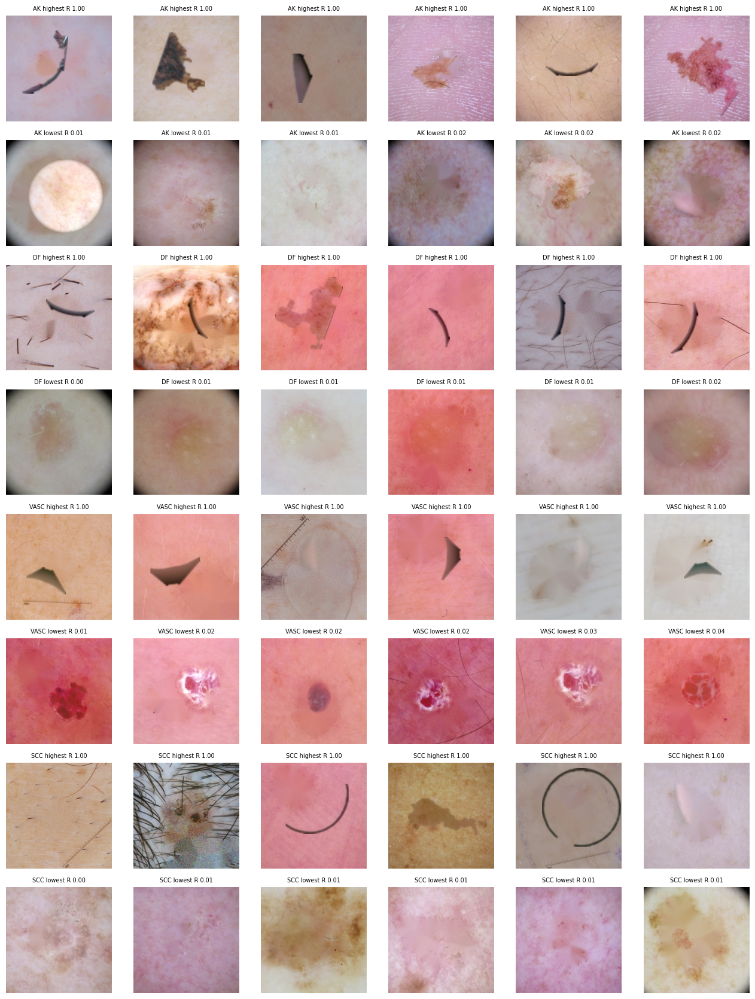

In [ ]:
# controls (seed 42): learned weights fixed, the same weights shuffled within each class, and a constant 0.5
Rw = np.load(RUN_DIR / 'bilevel_ce' / 'syn_weights.npy')
rs = np.random.default_rng(SEED); Rshuf = Rw.copy()
for c in TAIL:
    ii = np.where(syn['cls'].values == c)[0]; Rshuf[ii] = rs.permutation(Rw[ii])
for name, w in {'ce_L_synth_learnedR': Rw, 'ce_L_synth_shuffledR': Rshuf, 'ce_L_synth_w05': np.full(len(syn), 0.5)}.items():
    RES.setdefault(name, {})[42] = with_seed(42, run_std, name, loss='ce', use_synth=True, synth_w=w)
display(pd.DataFrame({k: {'test_BMA': RES[k][42]['test']['bma'], 'tail_recall': RES[k][42]['test']['tail_recall']}
                      for k in ['ce_L_synth_learnedR', 'ce_L_synth_shuffledR', 'ce_L_synth_w05']}).T.round(3))

# what the filter keeps and drops
fig, axes = plt.subplots(2 * len(TAIL), 6, figsize=(13, 2.1 * 2 * len(TAIL)))
for r_, c in enumerate(TAIL):
    ii = np.where(syn['cls'].values == c)[0]; o = ii[np.argsort(Rw[ii])]
    for row, sel, lab in [(2 * r_, o[::-1][:6], 'highest R'), (2 * r_ + 1, o[:6], 'lowest R')]:
        for j, k in enumerate(sel):
            axes[row, j].imshow(Image.open(SYN_DIR / syn.file[k])); axes[row, j].axis('off'); axes[row, j].set_title(f'{c} {lab} {Rw[k]:.2f}', fontsize=7)
plt.tight_layout(); plt.show()

## 11. Pseudo-labeling the unlabeled pool
The `la_L` model of the same seed is the **teacher**. Unlabeled images it labels with confidence >= tau are added to D_L, and a new student is trained with logit adjustment (prior of the actual training set). The hidden labels of the pool are used **only to score** the pseudo-labels, never for training. The threshold check (tau 0.6 and 0.9) uses one seed.

In [ ]:
def teacher_probs(s):
    f = RUN_DIR / f'pl_probs_s{s}.npy'
    if f.exists(): return np.load(f)
    net = make_model(); net.load_state_dict(torch.load(RUN_DIR / rname('la_L', s) / 'best.pt'))
    P = predict_paths(net, [CACHE_LOCAL / f'{n}.jpg' for n in tabU['image']]).softmax(1).numpy()
    np.save(f, P); del net; return P

def run_pl(name, tau=0.8, pl_w=1.0, seed_t=None):
    seed_t = SEED if seed_t is None else seed_t
    d = RUN_DIR / name; d.mkdir(exist_ok=True); rf = d / 'result.json'
    cfg = dict(TCFG, loss='la_pl', teacher='la_L', tau=tau, pl_w=pl_w)
    if rf.exists(): return load_done(name, rf, cfg)
    torch.manual_seed(SEED); np.random.seed(SEED); t0 = time.time()
    P = teacher_probs(seed_t); conf, yp = P.max(1), P.argmax(1); sel = np.where(conf >= tau)[0]
    q = dict(n=int(len(sel)), acc=float((yp[sel] == YU[sel]).mean()),
             per_class={c: dict(n=int((yp[sel] == k).sum()), prec=(float((YU[sel][yp[sel] == k] == k).mean()) if (yp[sel] == k).any() else None))
                        for k, c in enumerate(CLASSES)})
    print(f'{name}: kept {q["n"]} of {len(tabU)} pseudo-labels, accuracy {q["acc"]:.3f}')
    print('   per class (n, precision):', {c: (v['n'], None if v['prec'] is None else round(v['prec'], 2)) for c, v in q['per_class'].items()})
    paths = [CACHE_LOCAL / f'{i}.jpg' for i in tabs['L']['image']] + [CACHE_LOCAL / f'{n}.jpg' for n in tabU['image'].values[sel]]
    yt = torch.cat([Y['L'], torch.tensor(yp[sel])]); wt = torch.cat([torch.ones(len(Y['L'])), torch.full((len(sel),), float(pl_w))])
    cnt = torch.bincount(yt, weights=wt, minlength=K).float().clamp(min=1)               # prior of the ACTUAL training set
    model, bs_, be, hist = fit_std(paths, yt, wt, torch.ones(K, device=dev), torch.log(cnt / cnt.sum()).to(dev))
    return finish(name, d, rf, cfg, model, bs_, be, hist, t0, extra=dict(pl_quality=q))

setup_fold(SYN_FOLD)
run_method('pl_la_t08', run_pl, tau=0.8)
display(agg_table(['la_L', 'la_real_synth_w03', 'bilevel_la', 'pl_la_t08']))
paired('pl_la_t08', 'la_L'); paired('pl_la_t08', 'la_real_synth_w03')

plq = pd.DataFrame([dict(seed=s, kept=RES['pl_la_t08'][s]['pl_quality']['n'], accuracy=RES['pl_la_t08'][s]['pl_quality']['acc'],
                         **{f'prec_{c}': RES['pl_la_t08'][s]['pl_quality']['per_class'][c]['prec'] for c in CLASSES}) for s in SEEDS]).set_index('seed')
display(plq.round(2)); plq.to_csv(REPORT / 'pseudo_label_quality.csv')

for tau in (0.6, 0.9):                                    # threshold check, one seed
    run_method(f'pl_la_t{int(round(tau * 10)):02d}', run_pl, seeds=[42], tau=tau)
sw = pd.DataFrame([dict(tau=t, kept=RES[m][42]['pl_quality']['n'], pl_acc=RES[m][42]['pl_quality']['acc'],
                        test_BMA=RES[m][42]['test']['bma'], tail_recall=RES[m][42]['test']['tail_recall'])
                   for t, m in [(0.6, 'pl_la_t06'), (0.8, 'pl_la_t08'), (0.9, 'pl_la_t09')]]).set_index('tau')
sw.loc['la_L (no PL)'] = [0, np.nan, RES['la_L'][42]['test']['bma'], RES['la_L'][42]['test']['tail_recall']]
display(sw.round(3)); sw.to_csv(REPORT / 'pseudo_label_threshold.csv')

fold 0: L 2012 | meta 1058 | test 5004 | unlabeled 17257 | RAM 5.4/13.6 GB
pl_la_t08 -> already done, loaded
pl_la_t08_s1 -> already done, loaded
pl_la_t08_s2 -> already done, loaded


,n_seeds,BMA,BMA_sd,F1,tail_recall,R_MEL,R_NV,R_BCC,R_AK,R_BKL,R_DF,R_VASC,R_SCC
method,,,,,,,,,,,,,
la_L,3,0.496,0.014,0.445,0.379,0.573,0.750,0.677,0.333,0.452,0.333,0.645,0.206
la_real_synth_w03,3,0.498,0.008,0.445,0.397,0.516,0.779,0.635,0.420,0.466,0.327,0.697,0.145
bilevel_la,3,0.497,0.002,0.436,0.425,0.520,0.772,0.522,0.463,0.462,0.333,0.693,0.212
pl_la_t08,3,0.525,0.004,0.449,0.457,0.589,0.718,0.612,0.372,0.449,0.421,0.719,0.316


pl_la_t08 minus la_L: bma mean +0.029  per seed [0.042 0.02  0.024]
pl_la_t08 minus la_real_synth_w03: bma mean +0.026  per seed [0.019 0.021 0.039]


,kept,accuracy,prec_MEL,prec_NV,prec_BCC,prec_AK,prec_BKL,prec_DF,prec_VASC,prec_SCC
seed,,,,,,,,,,
42,7613,0.83,0.70,0.94,0.78,0.40,0.65,0.29,0.59,0.51
1,8588,0.78,0.61,0.94,0.76,0.28,0.70,0.20,0.62,0.43
2,9502,0.80,0.66,0.92,0.77,0.35,0.62,0.13,0.55,0.37


pl_la_t06 -> already done, loaded
pl_la_t09 -> already done, loaded


,kept,pl_acc,test_BMA,tail_recall
tau,,,,
0.6,11795.0,0.754,0.533,0.500
0.8,7613.0,0.832,0.519,0.402
0.9,4432.0,0.868,0.522,0.411
la_L (no PL),0.0,NaN,0.477,0.333


## 12. Official ISIC 2019 test set
An independent check: the saved fold-0 models are scored on the **6,191 official test images of the 8 known classes** (the 2,047 `UNK` images are excluded). No retraining happens here. The test images are resized with the same recipe as training and kept on the local disk only.

In [ ]:
assert HAS_TEST_LABELS, 'section 2 said the official test labels are not usable'
if FOLD != SYN_FOLD: setup_fold(SYN_FOLD)
TEST_LOCAL = LOCAL / 'test256'; TEST_LOCAL.mkdir(exist_ok=True)
tg = pd.read_csv(GT_TEST)
if 'UNK' in tg: tg = tg[tg['UNK'] == 0]
tg = tg.reset_index(drop=True); tg['label'] = tg[CLASSES].values.argmax(1)
print('official test images (known classes):', len(tg), tg[CLASSES].sum().astype(int).to_dict())

need = set(tg['image'])
if len(list(TEST_LOCAL.glob('*.jpg'))) < len(tg):
    with zipfile.ZipFile(ZIP_TEST) as z:
        for n in z.namelist():
            stem = Path(n).stem
            if stem in need and n.lower().endswith('.jpg') and not (TEST_LOCAL / f'{stem}.jpg').exists():
                im = Image.open(z.open(n)).convert('RGB'); w, h = im.size; s = IMG_SIZE / min(w, h)
                im = im.resize((max(IMG_SIZE, round(w * s)), max(IMG_SIZE, round(h * s))), Image.LANCZOS)
                w, h = im.size; l, t = (w - IMG_SIZE) // 2, (h - IMG_SIZE) // 2
                im.crop((l, t, l + IMG_SIZE, t + IMG_SIZE)).save(TEST_LOCAL / f'{stem}.jpg', quality=95)
assert len(list(TEST_LOCAL.glob('*.jpg'))) >= len(tg), 'some test images are missing from the zip'
X_off = load_tensor([TEST_LOCAL / f'{i}.jpg' for i in tg['image']]); Y_off = torch.tensor(tg['label'].values)

OFF = {}
for m in ['ce_L', 'wce_L', 'la_L', 'la_real_synth_w03', 'la_real_synth_w1', 'bilevel_la', 'pl_la_t06', 'pl_la_t08', 'pl_la_t09']:
    OFF[m] = {}
    for s in SEEDS:
        ck = RUN_DIR / rname(m, s) / 'best.pt'
        if not ck.exists(): continue                          # e.g. the threshold-check runs exist for seed 42 only
        net = make_model(); net.load_state_dict(torch.load(ck)); OFF[m][s] = metrics(predict(net, X_off), Y_off); del net
off = pd.DataFrame([dict(method=m, n_seeds=len(d), off_BMA=np.mean([v['bma'] for v in d.values()]), off_BMA_sd=np.std([v['bma'] for v in d.values()]),
                         off_F1=np.mean([v['macro_f1'] for v in d.values()]), off_tail_recall=np.mean([v['tail_recall'] for v in d.values()]),
                         **{f'R_{c}': np.mean([v['recall'][c] for v in d.values()]) for c in CLASSES}) for m, d in OFF.items()]).set_index('method')
off = off.round(3).sort_values('off_BMA', ascending=False); display(off); off.to_csv(REPORT / 'official_test_results.csv')
for a, b in [('la_L', 'wce_L'), ('pl_la_t08', 'la_L'), ('bilevel_la', 'la_L'), ('la_real_synth_w03', 'la_L')]:
    d = np.array([OFF[a][s]['bma'] - OFF[b][s]['bma'] for s in SEEDS]); print(f'OFFICIAL  {a} minus {b}: {d.mean():+.3f}  per seed {np.round(d, 3)}')
del X_off; gc.collect()

official test images (known classes): 6191 {'MEL': 1327, 'NV': 2495, 'BCC': 975, 'AK': 374, 'BKL': 660, 'DF': 91, 'VASC': 104, 'SCC': 165}
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 169MB/s]


,n_seeds,off_BMA,off_BMA_sd,off_F1,off_tail_recall,R_MEL,R_NV,R_BCC,R_AK,R_BKL,R_DF,R_VASC,R_SCC
method,,,,,,,,,,,,,
pl_la_t09,1,0.500,0.000,0.452,0.419,0.585,0.707,0.707,0.564,0.330,0.429,0.452,0.230
pl_la_t06,1,0.497,0.000,0.420,0.481,0.613,0.627,0.463,0.634,0.347,0.374,0.606,0.309
pl_la_t08,3,0.492,0.016,0.434,0.436,0.630,0.679,0.564,0.624,0.318,0.348,0.519,0.255
bilevel_la,3,0.467,0.003,0.413,0.418,0.572,0.729,0.448,0.596,0.315,0.326,0.542,0.208
la_L,3,0.466,0.009,0.429,0.373,0.603,0.705,0.620,0.540,0.309,0.264,0.458,0.230
la_real_synth_w03,3,0.461,0.012,0.422,0.370,0.591,0.732,0.573,0.537,0.312,0.308,0.468,0.168
la_real_synth_w1,3,0.457,0.011,0.420,0.357,0.576,0.740,0.578,0.485,0.333,0.278,0.545,0.119
wce_L,3,0.445,0.011,0.438,0.315,0.621,0.730,0.657,0.504,0.294,0.121,0.426,0.210
ce_L,3,0.412,0.003,0.422,0.219,0.629,0.787,0.709,0.451,0.293,0.044,0.260,0.123


OFFICIAL  la_L minus wce_L: +0.021  per seed [0.024 0.017 0.02 ]
OFFICIAL  pl_la_t08 minus la_L: +0.026  per seed [0.017 0.036 0.025]
OFFICIAL  bilevel_la minus la_L: +0.001  per seed [-0.001 -0.012  0.015]
OFFICIAL  la_real_synth_w03 minus la_L: -0.005  per seed [-0.02  -0.005  0.009]


543

## 12b. Inference boosts on the saved models: 4x flip TTA and a 3-seed ensemble (no retraining)
`single` = mean over the 3 seeds; `ens` = average of the 3 seeds' probabilities; `_tta` = 4 flipped views averaged. Report these as separate rows, never in place of the single-model numbers.

In [ ]:
BOOST = ROOT / 'boost'; BOOST.mkdir(exist_ok=True)
assert FOLD == SYN_FOLD, 'run this cell right after section 12 (before section 13 changes the fold)'
X_off = load_tensor([TEST_LOCAL / f'{i}.jpg' for i in tg['image']])                   # official test set (tg, TEST_LOCAL, Y_off come from section 12)
Xd = {'test': X['test'], 'off': X_off}; Yd = {'test': Y['test'], 'off': Y_off}

@torch.no_grad()
def predict_both(model, x, bs=128):
    """(plain logits, 4x-TTA logits): original + H-flip + V-flip + HV-flip, logits averaged."""
    model.eval(); plain, tta = [], []
    for i in range(0, len(x), bs):
        xb = tf_eval(x[i:i + bs].to(dev))
        with torch.autocast('cuda', dtype=torch.float16):
            l0 = model(xb).float(); l1 = model(xb.flip(3)).float(); l2 = model(xb.flip(2)).float(); l3 = model(xb.flip([2, 3])).float()
        plain.append(l0.cpu()); tta.append(((l0 + l1 + l2 + l3) / 4).cpu())
    return torch.cat(plain), torch.cat(tta)

METHODS_A = ['wce_L', 'la_L', 'la_real_synth_w03', 'bilevel_la', 'pl_la_t08']
def collect(run_root, methods, label):
    P = {}
    for m in methods:
        for s in SEEDS:
            ck, f = run_root / rname(m, s) / 'best.pt', BOOST / f'{label}_{m}_s{s}.pt'
            if f.exists(): P[(m, s)] = torch.load(f); continue
            if not ck.exists(): print('missing', ck); continue
            net = make_model(); net.load_state_dict(torch.load(ck))
            r = {k: predict_both(net, Xd[k]) for k in ('test', 'off')}
            torch.save(r, f); P[(m, s)] = r; del net; gc.collect(); torch.cuda.empty_cache(); print('done', label, m, s)
    return P

def table(P, methods):
    rows = []
    for m in methods:
        ss = [s for s in SEEDS if (m, s) in P]
        if not ss: continue
        row = dict(method=m, n_seeds=len(ss))
        for k in ('test', 'off'):
            for i, tag in ((0, ''), (1, '_tta')):
                row[f'{k}_single{tag}'] = np.mean([metrics(P[(m, s)][k][i], Yd[k])['bma'] for s in ss])
                e = metrics(torch.stack([P[(m, s)][k][i].softmax(1) for s in ss]).mean(0), Yd[k])
                row[f'{k}_ens{tag}'] = e['bma']
                if i == 1: row[f'{k}_ens_tta_tail'] = e['tail_recall']
        rows.append(row)
    return pd.DataFrame(rows).set_index('method').round(3)

P_old = collect(RUNS / f'fold{SYN_FOLD}', METHODS_A, 'old')
tA = table(P_old, METHODS_A)
display(tA[['n_seeds', 'test_single', 'test_single_tta', 'test_ens', 'test_ens_tta', 'test_ens_tta_tail']])
display(tA[['off_single', 'off_single_tta', 'off_ens', 'off_ens_tta', 'off_ens_tta_tail']])
tA.to_csv(REPORT / 'boost_partA_tta_ensemble.csv')
del X_off, Xd; gc.collect()

,n_seeds,test_single,test_single_tta,test_ens,test_ens_tta,test_ens_tta_tail
method,,,,,,
wce_L,3,0.462,0.471,0.473,0.478,0.302
la_L,3,0.496,0.500,0.513,0.518,0.397
la_real_synth_w03,3,0.498,0.499,0.508,0.520,0.413
bilevel_la,3,0.497,0.500,0.524,0.530,0.452
pl_la_t08,3,0.525,0.527,0.548,0.545,0.463


,off_single,off_single_tta,off_ens,off_ens_tta,off_ens_tta_tail
method,,,,,
wce_L,0.446,0.458,0.462,0.466,0.331
la_L,0.466,0.474,0.490,0.493,0.402
la_real_synth_w03,0.461,0.468,0.485,0.488,0.408
bilevel_la,0.468,0.474,0.484,0.487,0.433
pl_la_t08,0.492,0.498,0.516,0.514,0.458


0

## 12c. Early-stopping replay on the saved training histories (no retraining)
Patience 5, minimum gain 0.002 on meta BMA. `same_final_model` = the rule would have kept exactly the weights of the fixed 15-epoch run.

In [ ]:
PATIENCE, MIN_DELTA = 5, 0.002

def replay(vals, patience, smooth=1, delta=MIN_DELTA):
    """Replay an early-stopping rule on the saved per-epoch meta BMA. smooth=3 -> the STOP decision uses a trailing 3-epoch mean,
    but the weights kept are always the best RAW epoch seen before stopping. Returns (stop epoch, kept epoch)."""
    v = np.array(vals, dtype=float)
    s = np.array([v[max(0, i - smooth + 1):i + 1].mean() for i in range(len(v))])
    best, bad = -1.0, 0
    for ep, x in enumerate(s):
        if x > best:
            gain = x - best; best = x
            bad = 0 if gain > delta else bad + 1
        else:
            bad += 1
        if bad >= patience: return ep, int(np.argmax(v[:ep + 1]))
    return len(v) - 1, int(np.argmax(v))

rows = []
for m in ['wce_L', 'la_L', 'la_real_synth_w03', 'bilevel_la', 'pl_la_t08']:
    for s in SEEDS:
        rf = RUNS / 'fold0' / rname(m, s) / 'result.json'
        if not rf.exists(): continue
        r = json.load(open(rf)); h = r.get('hist') or []
        if not h or 'meta_bma' not in h[0]: continue
        mb = [e['meta_bma'] for e in h]
        for rule, sm in (('raw', 1), ('smoothed3', 3)):
            stop, pick = replay(mb, PATIENCE, smooth=sm)
            rows.append(dict(method=m, seed=s, rule=rule, epochs_run=len(h), stops_after=stop + 1,
                             epochs_saved_pct=round(100 * (len(h) - stop - 1) / len(h)),
                             old_best_epoch=r['best_epoch'], kept_epoch=pick, same_final_model=(pick == r['best_epoch']),
                             meta_bma_old=round(mb[r['best_epoch']], 3), meta_bma_kept=round(mb[pick], 3)))
rep = pd.DataFrame(rows)
summary = (rep.groupby(['rule', 'method'])
              .agg(avg_stops_after=('stops_after', 'mean'), avg_epochs_saved_pct=('epochs_saved_pct', 'mean'),
                   same_model_runs=('same_final_model', 'sum'), n_runs=('seed', 'count'),
                   meta_bma_old=('meta_bma_old', 'mean'), meta_bma_kept=('meta_bma_kept', 'mean')).round(3))
display(summary)
print('Runs where early stopping keeps exactly the same weights as the fixed 15-epoch run:'); print(rep.groupby('rule')['same_final_model'].agg(['sum', 'count']))
rep.to_csv(REPORT / 'early_stopping_replay.csv', index=False); summary.to_csv(REPORT / 'early_stopping_replay_summary.csv')

avg_stops_after  avg_epochs_saved_pct  \
rule      method                                                     
raw       bilevel_la                   9.333                37.667   
          la_L                        11.667                22.000   
          la_real_synth_w03            9.000                40.000   
          pl_la_t08                    8.333                44.333   
          wce_L                       10.000                33.333   
smoothed3 bilevel_la                   9.333                37.667   
          la_L                        12.333                17.667   
          la_real_synth_w03           13.333                11.000   
          pl_la_t08                   11.000                26.667   
          wce_L                        8.667                42.000   

                             same_model_runs  n_runs  meta_bma_old  \
rule      method                                                     
raw       bilevel_la                       3       3         0.536   
          la_L                             3       3         0.516   
          la_real_synth_w03                3       3         0.524   
          pl_la_t08                        2       3         0.559   
          wce_L                            2       3         0.457   
smoothed3 bilevel_la                       3       3         0.536   
          la_L                             3       3         0.516   
          la_real_synth_w03                3       3         0.524   
          pl_la_t08                        3       3         0.559   
          wce_L                            2       3         0.457   

                             meta_bma_kept  
rule      method                            
raw       bilevel_la                 0.536  
          la_L                       0.516  
          la_real_synth_w03          0.524  
          pl_la_t08                  0.555  
          wce_L                      0.456  
smoothed3 bilevel_la                 0.536  
          la_L                       0.516  
          la_real_synth_w03          0.524  
          pl_la_t08                  0.559  
          wce_L                      0.456

Runs where early stopping keeps exactly the same weights as the fixed 15-epoch run:
           sum  count
rule                 
raw         13     15
smoothed3   14     15


## 13. Five folds
The key methods on all 5 folds (seed 42 each), so the conclusions do not rest on one split. No synthetic data is needed, so the other folds only need the splits and the image cache. Each fold's pseudo-label model uses that fold's own `la_L` as its teacher. Finished runs are loaded, so this cell can be re-run after a disconnect.

fold 0: L 2012 | meta 1058 | test 5004 | unlabeled 17257 | RAM 6.0/13.6 GB
ce_L -> already done, loaded
wce_L -> already done, loaded
la_L -> already done, loaded
pl_la_t08 -> already done, loaded
fold 1: L 2022 | meta 1010 | test 5104 | unlabeled 17195 | RAM 6.1/13.6 GB
ce_L -> already done, loaded
wce_L -> already done, loaded
la_L -> already done, loaded
pl_la_t08 -> already done, loaded
fold 2: L 2062 | meta 1013 | test 5011 | unlabeled 17245 | RAM 6.0/13.6 GB
ce_L -> already done, loaded
wce_L -> already done, loaded
la_L -> already done, loaded
pl_la_t08 -> already done, loaded
fold 3: L 2016 | meta 1004 | test 5125 | unlabeled 17186 | RAM 6.1/13.6 GB
ce_L -> already done, loaded
wce_L -> already done, loaded
la_L -> already done, loaded
pl_la_t08 -> already done, loaded
fold 4: L 2104 | meta 986 | test 5087 | unlabeled 17154 | RAM 6.1/13.6 GB
ce_L -> already done, loaded
wce_L -> already done, loaded
la_L -> already done, loaded
pl_la_t08 -> already done, loaded


,test_BMA_mean,test_BMA_sd,test_F1_mean,tail_recall_mean,tail_recall_sd
method,,,,,
pl_la_t08,0.508,0.019,0.434,0.423,0.041
la_L,0.489,0.009,0.424,0.389,0.029
wce_L,0.469,0.019,0.439,0.346,0.034
ce_L,0.421,0.035,0.427,0.236,0.052


method,ce_L,la_L,pl_la_t08,wce_L
fold,,,,
0,0.432,0.477,0.519,0.470
1,0.472,0.499,0.539,0.499
2,0.373,0.484,0.502,0.441
3,0.434,0.499,0.485,0.476
4,0.391,0.486,0.495,0.459


la_L minus wce_L: mean +0.020  per fold [ 0.007 -0.     0.043  0.024  0.028]  (better in 4/5 folds)
la_L minus ce_L: mean +0.069  per fold [0.045 0.027 0.111 0.065 0.095]  (better in 5/5 folds)
pl_la_t08 minus la_L: mean +0.019  per fold [ 0.042  0.04   0.018 -0.014  0.009]  (better in 4/5 folds)


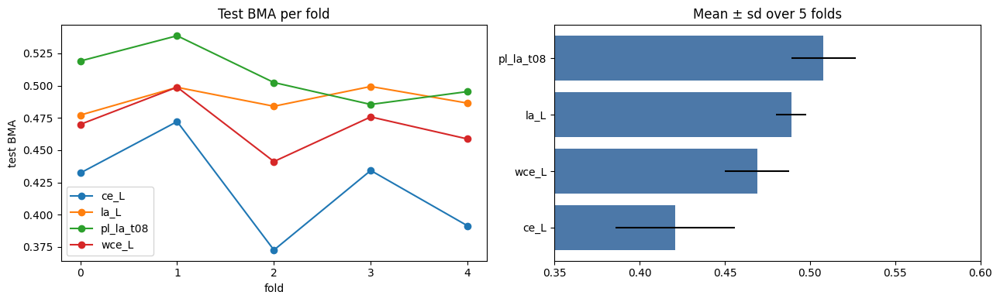

fold 0: L 2012 | meta 1058 | test 5004 | unlabeled 17257 | RAM 6.1/13.6 GB


In [ ]:
FIVE = {}
for k in range(N_FOLDS):
    setup_fold(k); FIVE[k] = {}
    for m, fn, kw in [('ce_L', run_std, dict(loss='ce')), ('wce_L', run_std, dict(loss='wce')), ('la_L', run_std, dict(loss='la')),
                      ('pl_la_t08', run_pl, dict(tau=0.8))]:
        FIVE[k][m] = with_seed(42, fn, m, **kw)

five = pd.DataFrame([dict(fold=k, method=m, test_BMA=r['test']['bma'], test_F1=r['test']['macro_f1'], tail_recall=r['test']['tail_recall'],
                          **{f'R_{c}': r['test']['recall'][c] for c in CLASSES}) for k, d in FIVE.items() for m, r in d.items()])
five.to_csv(REPORT / 'five_fold_per_fold.csv', index=False)
summ = five.groupby('method')[['test_BMA', 'test_F1', 'tail_recall'] + [f'R_{c}' for c in CLASSES]].agg(['mean', lambda x: x.std(ddof=0)])
summ.columns = [f'{a}_{"mean" if b == "mean" else "sd"}' for a, b in summ.columns]
summ = summ.sort_values('test_BMA_mean', ascending=False).round(3); summ.to_csv(REPORT / 'five_fold_summary.csv')
display(summ[['test_BMA_mean', 'test_BMA_sd', 'test_F1_mean', 'tail_recall_mean', 'tail_recall_sd']])
piv = five.pivot(index='fold', columns='method', values='test_BMA'); display(piv.round(3))
for a, b in [('la_L', 'wce_L'), ('la_L', 'ce_L'), ('pl_la_t08', 'la_L')]:
    dd = (piv[a] - piv[b]).values; print(f'{a} minus {b}: mean {dd.mean():+.3f}  per fold {np.round(dd, 3)}  (better in {(dd > 0).sum()}/{len(dd)} folds)')
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for m in piv.columns: ax[0].plot(piv.index, piv[m], marker='o', label=m)
ax[0].set_xlabel('fold'); ax[0].set_ylabel('test BMA'); ax[0].set_xticks(range(N_FOLDS)); ax[0].legend(); ax[0].set_title('Test BMA per fold')
o = summ.index[::-1]; ax[1].barh(o, summ.loc[o, 'test_BMA_mean'], xerr=summ.loc[o, 'test_BMA_sd'], color='#4c78a8'); ax[1].set_xlim(0.35, 0.6)
ax[1].set_title('Mean ± sd over 5 folds'); plt.tight_layout(); plt.savefig(REPORT / 'fig_five_fold.png', dpi=200); plt.show()
setup_fold(SYN_FOLD)                                          # back to fold 0

## 14. Summary tables and figures (fold 0, 3 seeds), saved to `DS_PROJECT/report/`

,test_BMA_mean,test_BMA_sd,test_F1_mean,tail_recall_mean,tail_recall_sd
method,,,,,
pl_la_t08,0.525,0.004,0.449,0.457,0.039
la_real_synth_w03,0.498,0.008,0.445,0.397,0.010
bilevel_la,0.497,0.002,0.436,0.425,0.034
la_L,0.496,0.014,0.445,0.379,0.033
la_real_synth_w1,0.478,0.008,0.438,0.339,0.024
wce_L,0.462,0.006,0.455,0.297,0.008
la_L_synth_w1,0.450,0.012,0.458,0.238,0.026
wce_L_synth_w1,0.445,0.009,0.452,0.227,0.031
bilevel_wce,0.445,0.020,0.450,0.230,0.041


la_L minus wce_L: BMA mean +0.034 (per seed [0.007 0.046 0.048]) | tail recall mean +0.082
la_L minus ce_L: BMA mean +0.058 (per seed [0.045 0.068 0.06 ]) | tail recall mean +0.151
pl_la_t08 minus la_L: BMA mean +0.029 (per seed [0.042 0.02  0.024]) | tail recall mean +0.078
la_real_synth_w03 minus la_L: BMA mean +0.002 (per seed [ 0.023 -0.002 -0.015]) | tail recall mean +0.018
la_real_synth_w1 minus la_L: BMA mean -0.018 (per seed [-0.01  -0.024 -0.021]) | tail recall mean -0.041
bilevel_la minus la_L: BMA mean +0.001 (per seed [ 0.023 -0.012 -0.007]) | tail recall mean +0.046
bilevel_la minus la_real_synth_w1: BMA mean +0.020 (per seed [0.033 0.012 0.013]) | tail recall mean +0.086
bilevel_la minus la_real_synth_w03: BMA mean -0.001 (per seed [-0.001 -0.01   0.008]) | tail recall mean +0.028
bilevel_wce minus wce_L_synth_w1: BMA mean -0.000 (per seed [ 0.022 -0.003 -0.02 ]) | tail recall mean +0.003
bilevel_ce minus ce_L_synth_w1: BMA mean -0.005 (per seed [ 0.011 -0.043  0.018]) | 

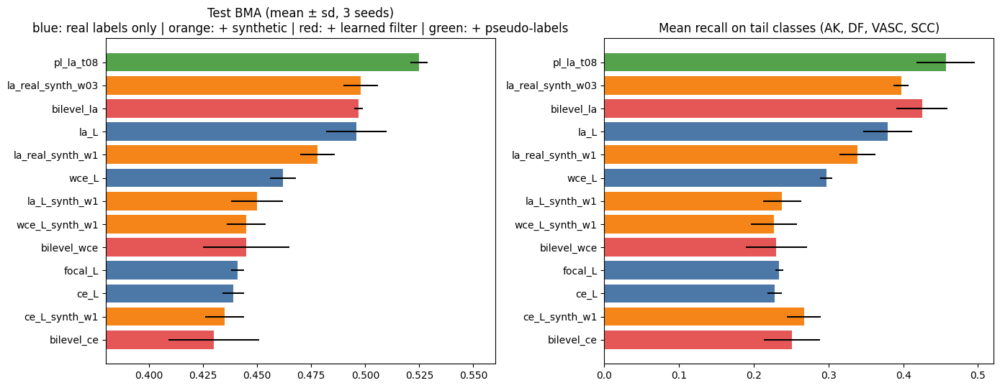

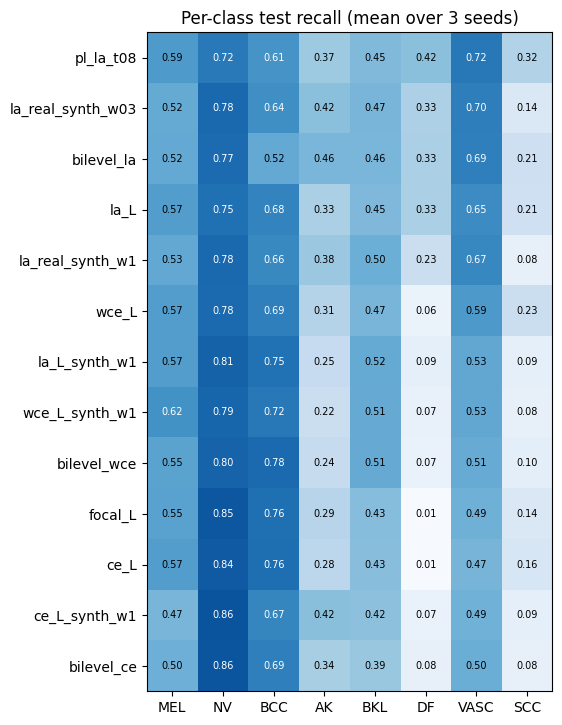

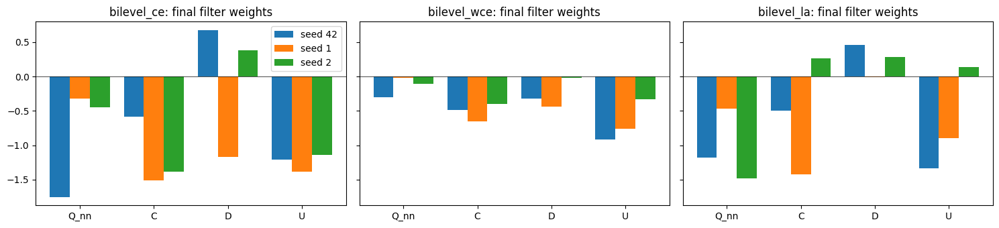

saved: ['all_runs_per_seed.csv', 'boost_final_comparison.csv', 'boost_partA_tta_ensemble.csv', 'early_stopping_replay.csv', 'early_stopping_replay_summary.csv', 'fig_filter_weights.png', 'fig_five_fold.png', 'fig_methods.png', 'fig_per_class_recall.png', 'final_headline_table.csv', 'five_fold_per_fold.csv', 'five_fold_summary.csv', 'headline_bma.png', 'mask_refinement_stats.csv', 'mask_refinement_v2_status.csv', 'official_test_pseudo_label.csv', 'official_test_results.csv', 'official_test_selftrain.csv', 'paired_differences.txt', 'pseudo_label_quality.csv', 'pseudo_label_threshold.csv', 'report_sentences.md', 'summary_mean_sd.csv']


In [ ]:
raw = pd.DataFrame([dict(method=m, seed=s, best_epoch=r['best_epoch'], meta_BMA=r['meta']['bma'], test_BMA=r['test']['bma'],
                         test_F1=r['test']['macro_f1'], test_acc=r['test']['acc'], tail_recall=r['test']['tail_recall'],
                         **{f'R_{c}': r['test']['recall'][c] for c in CLASSES}) for m in RES for s, r in RES[m].items()])
raw.to_csv(REPORT / 'all_runs_per_seed.csv', index=False)
num = [c for c in raw.columns if c not in ('method', 'seed')]
agg = raw[raw['method'].isin([m for m in RES if len(RES[m]) == len(SEEDS)])].groupby('method')[num].agg(['mean', lambda x: x.std(ddof=0)])
agg.columns = [f'{a}_{"mean" if b == "mean" else "sd"}' for a, b in agg.columns]
agg = agg.sort_values('test_BMA_mean', ascending=False).round(3); agg.to_csv(REPORT / 'summary_mean_sd.csv')
display(agg[['test_BMA_mean', 'test_BMA_sd', 'test_F1_mean', 'tail_recall_mean', 'tail_recall_sd']])

pairs = [('la_L', 'wce_L'), ('la_L', 'ce_L'), ('pl_la_t08', 'la_L'), ('la_real_synth_w03', 'la_L'), ('la_real_synth_w1', 'la_L'), ('bilevel_la', 'la_L'),
         ('bilevel_la', 'la_real_synth_w1'), ('bilevel_la', 'la_real_synth_w03'), ('bilevel_wce', 'wce_L_synth_w1'), ('bilevel_ce', 'ce_L_synth_w1')]
lines = []
for a, b in pairs:
    dB = np.array([RES[a][s]['test']['bma'] - RES[b][s]['test']['bma'] for s in SEEDS])
    dT = np.array([RES[a][s]['test']['tail_recall'] - RES[b][s]['test']['tail_recall'] for s in SEEDS])
    lines.append(f'{a} minus {b}: BMA mean {dB.mean():+.3f} (per seed {np.round(dB, 3)}) | tail recall mean {dT.mean():+.3f}')
print('\n'.join(lines)); (REPORT / 'paired_differences.txt').write_text('\n'.join(lines))

grp = lambda m: '#e45756' if 'bilevel' in m else '#54a24b' if m.startswith('pl_') else '#f58518' if 'synth' in m else '#4c78a8'
order = agg.index[::-1]
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
ax[0].barh(order, agg.loc[order, 'test_BMA_mean'], xerr=agg.loc[order, 'test_BMA_sd'], color=[grp(m) for m in order]); ax[0].set_xlim(0.38, 0.56)
ax[0].set_title('Test BMA (mean ± sd, 3 seeds)\nblue: real labels only | orange: + synthetic | red: + learned filter | green: + pseudo-labels')
ax[1].barh(order, agg.loc[order, 'tail_recall_mean'], xerr=agg.loc[order, 'tail_recall_sd'], color=[grp(m) for m in order]); ax[1].set_title('Mean recall on tail classes (AK, DF, VASC, SCC)')
plt.tight_layout(); plt.savefig(REPORT / 'fig_methods.png', dpi=200); plt.show()

hm = agg[[f'R_{c}_mean' for c in CLASSES]]; hm.columns = CLASSES
fig, ax = plt.subplots(figsize=(9, 0.45 * len(hm) + 1.5)); ax.imshow(hm.values, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(K)); ax.set_xticklabels(CLASSES); ax.set_yticks(range(len(hm))); ax.set_yticklabels(hm.index)
for i in range(len(hm)):
    for j in range(K): ax.text(j, i, f'{hm.values[i, j]:.2f}', ha='center', va='center', fontsize=7, color='white' if hm.values[i, j] > .6 else 'black')
ax.set_title('Per-class test recall (mean over 3 seeds)'); plt.tight_layout(); plt.savefig(REPORT / 'fig_per_class_recall.png', dpi=200); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
for a, m in zip(ax, ['bilevel_ce', 'bilevel_wce', 'bilevel_la']):
    for k, s in enumerate(SEEDS): a.bar(np.arange(4) + k * 0.27, RES[m][s]['hist'][-1]['w'], 0.27, label=f'seed {s}')
    a.set_xticks(np.arange(4) + 0.27); a.set_xticklabels(FEATS); a.axhline(0, color='k', lw=.5); a.set_title(f'{m}: final filter weights')
ax[0].legend(); plt.tight_layout(); plt.savefig(REPORT / 'fig_filter_weights.png', dpi=200); plt.show()
print('saved:', sorted(p.name for p in REPORT.glob('*')))

## 14b. Headline table, figure and report sentences

,fold0_single,fold0_ens_tta,fold0_tail_recall,official_single,official_ens_tta,official_tail_recall,fold0_gain,official_gain
method,,,,,,,,
pl_la_t08,0.525,0.545,0.463,0.492,0.514,0.458,0.020,0.022
la_L,0.496,0.518,0.397,0.466,0.493,0.402,0.022,0.027
la_real_synth_w03,0.498,0.520,0.413,0.461,0.488,0.408,0.022,0.027
bilevel_la,0.497,0.530,0.452,0.468,0.487,0.433,0.033,0.019
wce_L,0.462,0.478,0.302,0.446,0.466,0.331,0.016,0.020


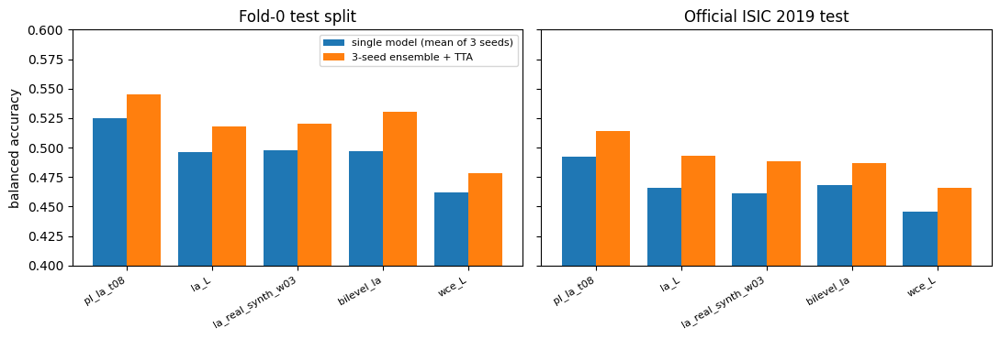

Best method: pl_la_t08. Official test BMA 0.492 (single model) and 0.514 (3-seed ensemble + 4x flip TTA); fold-0 test 0.525 and 0.545.

Averaged over the methods, the ensemble with TTA adds 2.3 points on the fold-0 test split and 2.3 points on the official test set. These are inference-time gains and are reported separately from the single-model results.

A deeper backbone (EfficientNet-B2, 256 px, up to 30 epochs with early stopping) did not help: single-model BMA 0.465 vs 0.496 for la_L and 0.479 vs 0.525 for pl_la_t08, so the EfficientNet-B0 pipeline was kept.

Automatic early stopping (patience 5 epochs, minimum gain 0.002 on meta-set BMA), replayed on the saved histories of 15 runs, keeps the same final model in 13 of them and skips on average 35% of the epochs.

Lesion masks of the 187 labeled tail images were re-segmented with GrabCut restricted to the dermoscope field of view; 139 masks pass the quality checks (136 refined, 3 old masks kept) and 48 are flagged unusable.

saved:

In [ ]:
tA = pd.read_csv(REPORT / 'boost_partA_tta_ensemble.csv', index_col='method')
head = pd.DataFrame({
    'fold0_single':   tA['test_single'],   'fold0_ens_tta':   tA['test_ens_tta'],   'fold0_tail_recall': tA['test_ens_tta_tail'],
    'official_single': tA['off_single'],   'official_ens_tta': tA['off_ens_tta'],   'official_tail_recall': tA['off_ens_tta_tail']})
head['fold0_gain'] = head['fold0_ens_tta'] - head['fold0_single']; head['official_gain'] = head['official_ens_tta'] - head['official_single']
head = head.sort_values('official_ens_tta', ascending=False).round(3)
display(head); head.to_csv(REPORT / 'final_headline_table.csv')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (k, ttl) in zip(axes, [('fold0', 'Fold-0 test split'), ('official', 'Official ISIC 2019 test')]):
    x = np.arange(len(head)); ax.bar(x - 0.2, head[f'{k}_single'], 0.4, label='single model (mean of 3 seeds)'); ax.bar(x + 0.2, head[f'{k}_ens_tta'], 0.4, label='3-seed ensemble + TTA')
    ax.set_xticks(x); ax.set_xticklabels(head.index, rotation=30, ha='right', fontsize=8); ax.set_title(ttl); ax.set_ylim(0.4, 0.6)
axes[0].set_ylabel('balanced accuracy'); axes[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(REPORT / 'headline_bma.png', dpi=200); plt.show()

L = []
best = head.index[0]
L.append(f'Best method: {best}. Official test BMA {head.loc[best, "official_single"]:.3f} (single model) and {head.loc[best, "official_ens_tta"]:.3f} '
         f'(3-seed ensemble + 4x flip TTA); fold-0 test {head.loc[best, "fold0_single"]:.3f} and {head.loc[best, "fold0_ens_tta"]:.3f}.')
L.append(f'Averaged over the methods, the ensemble with TTA adds {head["fold0_gain"].mean() * 100:.1f} points on the fold-0 test split and {head["official_gain"].mean() * 100:.1f} points on the official test set. These are inference-time gains and are reported separately from the single-model results.')
f_ = REPORT / 'boost_final_comparison.csv'
if f_.exists():
    fc = pd.read_csv(f_, index_col='method')
    if {'la_L_new', 'pl_la_t08_new'} <= set(fc.index):
        L.append(f'A deeper backbone (EfficientNet-B2, 256 px, up to 30 epochs with early stopping) did not help: single-model BMA {fc.loc["la_L_new", "test_single"]:.3f} vs {fc.loc["la_L", "test_single"]:.3f} for la_L and '
                 f'{fc.loc["pl_la_t08_new", "test_single"]:.3f} vs {fc.loc["pl_la_t08", "test_single"]:.3f} for pl_la_t08, so the EfficientNet-B0 pipeline was kept.')
f_ = REPORT / 'early_stopping_replay.csv'
if f_.exists():
    r = pd.read_csv(f_); r = r[r['rule'] == 'raw']
    L.append(f'Automatic early stopping (patience 5 epochs, minimum gain 0.002 on meta-set BMA), replayed on the saved histories of {len(r)} runs, keeps the same final model in {int(r["same_final_model"].sum())} of them '
             f'and skips on average {r["epochs_saved_pct"].mean():.0f}% of the epochs.')
f_ = REPORT / 'mask_refinement_v2_status.csv'
if f_.exists():
    m = pd.read_csv(f_)
    L.append(f'Lesion masks of the {len(m)} labeled tail images were re-segmented with GrabCut restricted to the dermoscope field of view; {int((m["status"] != "bad").sum())} masks pass the quality checks '
             f'({int((m["status"] == "refined").sum())} refined, {int((m["status"] == "old_ok").sum())} old masks kept) and {int((m["status"] == "bad").sum())} are flagged unusable.')
open(REPORT / 'report_sentences.md', 'w').write('\n\n'.join(L))
print('\n\n'.join(L)); print('\nsaved: final_headline_table.csv, headline_bma.png, report_sentences.md in', REPORT)

## Recorded results (from the original runs; the cells above regenerate them)
Test BMA = balanced accuracy over the 8 classes. Fold 0, mean over 3 training seeds unless stated.

| method | BMA | tail recall |
|---|---|---|
| plain CE (`ce_L`) | 0.439 | 0.228 |
| class-weighted CE (`wce_L`) | 0.462 | 0.297 |
| focal loss | 0.441 | 0.234 |
| **logit adjustment (`la_L`)** | **0.496** | 0.379 |
| LA + synthetic at weight 1 (real prior) | 0.478 | 0.339 |
| LA + synthetic at weight 0.3 | 0.498 | 0.397 |
| LA + synthetic + learned filter (`bilevel_la`) | 0.497 | 0.425 |

**Five folds** (seed 42): pseudo-labeling 0.508 ± 0.019, logit adjustment 0.489 ± 0.009, weighted CE 0.469 ± 0.019, plain CE 0.421 ± 0.035. Pseudo-labeling beat `la_L` in 4 of 5 folds (+0.019 on average; fold 3 was -0.014). Logit adjustment beat plain CE in 5 of 5 folds.

**Official test set** (6,191 images, fold-0 models, 3 seeds): `la_L` 0.466, `wce_L` 0.445, `ce_L` 0.412, pseudo-label model 0.492 (+0.026 over `la_L`, positive for every seed), `bilevel_la` 0.467.

**Reading.** Logit adjustment is the strongest loss. Pseudo-labeling the unlabeled pool adds a modest, mostly consistent gain. Copy-paste synthetic images do not help reliably, and the learned filter does not beat its controls: mainly it learned to turn the synthetic weight down. A linear probe separates real from synthetic tail images almost perfectly (AUC 0.988), which is a likely reason. Pseudo-label precision is high for NV (about 0.92) but low for the tail (AK about 0.3, DF about 0.2, SCC about 0.3).

**Limitations.** Synthetic-data methods were evaluated on fold 0 only; seeds vary training randomness but share one split, one synthetic set and one background bank; the meta set also selects the best epoch; classical masks fail on some images; DF and VASC have very few labeled and test images; the threshold check (tau 0.6 / 0.9) uses one seed.